# Gold futures — Exploratory Data Analysis

**Dataset:** `gold.csv`  
**Nguồn:** Yahoo Finance, ticker GC=F  
**Vai trò trong dự án:** Chuỗi trung tâm của bài toán Gold phiên kế tiếp.

## Mục tiêu phân tích

1. Hiểu cấu trúc, chất lượng, phân phối và phạm vi thời gian của nguồn dữ liệu.
2. Từ câu hỏi đặc thù của dataset, xây dựng các feature ứng viên và mô tả chúng.
3. Ghi nhận bằng chứng cần có trước khi quyết định giữ feature cho bài toán Gold phiên kế tiếp.

## Cấu trúc notebook

- **Part 1 — Data Profiling:** chỉ phân tích biến gốc.
- **Part 2 — Feature-oriented EDA:** câu hỏi → đại lượng cần đo → feature → EDA.

**Giới hạn:** dữ liệu daily hiện chỉ có ngày; không gán 00:00 thành giờ đóng cửa. EDA toàn kỳ chỉ dùng mô tả, không chọn lag/window/ngưỡng/feature theo kết quả toàn kỳ.



**Phạm vi:** snapshot EDA 2010–2026 của bốn nguồn Yahoo Finance; dữ liệu modeling 2005–2026 được xử lý riêng.

## Part 1 — Data Profiling

Phần này trả lời: dữ liệu có gì, có sạch không, phân phối cơ bản ra sao và trải dài trong thời gian nào? Chưa tạo return, MA, RSI hoặc MACD.


### 1.1 Thư viện và nguồn dữ liệu

In [1]:
from pathlib import Path



In [2]:

import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'data/modeling/horizons').is_dir() and (p/'notebook').is_dir())
DATA_DIR = ROOT / 'data/eda_2010_2026'
FILE_NAME = 'gold.csv'
DATA_PATH = DATA_DIR / FILE_NAME
RAW_NUMERIC = ['Open', 'High', 'Low', 'Close', 'Volume']
TITLE = 'Gold futures'


pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 100,
                     'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.25})

### 1.2 Đọc dữ liệu và chuẩn hóa định dạng

Chuẩn hóa tên Date, parse ngày và numeric trên bản sao. Đếm lỗi chuyển đổi; không impute và không xóa quan sát. Hai dòng metadata Yahoo không phải quan sát thị trường.


In [3]:

metadata = pd.read_csv(DATA_PATH, nrows=2)
print('\nThông tin metadata của file nguồn')
display(metadata)

if metadata.iloc[0, 0] == 'Ticker' and metadata.iloc[1, 0] == 'Date':
    print('Metadata đúng định dạng Ticker/Date.')
else:
    print('Cảnh báo: Metadata không đúng định dạng Ticker/Date dự kiến; cần kiểm tra cách đọc file.')

if (metadata.iloc[0, 1:] == 'GC=F').all():
    print('Ticker đúng nguồn dự kiến.')
else:
    print('Cảnh báo: Ticker không đúng nguồn dự kiến.')

raw = pd.read_csv(DATA_PATH, skiprows=[1, 2])

if set(raw.columns) == {'Price', 'Open', 'High', 'Low', 'Close', 'Volume'}:
    print('Các cột đúng schema dự kiến.')
else:
    print('Cảnh báo: Các cột trong file khác schema dự kiến; xem tên cột trước khi phân tích tiếp.')

df = raw.rename(columns={'Price': 'Date'}).copy()


original_dates = df['Date'].copy()
df['Date'] = pd.to_datetime(df['Date'], format='%Y-%m-%d', errors='coerce')
parse_failures = {'Date': int((original_dates.notna() & df['Date'].isna()).sum())}

for column in RAW_NUMERIC:
    original_values = df[column].copy()
    df[column] = pd.to_numeric(original_values, errors='coerce')
    parse_failures[column] = int((original_values.notna() & df[column].isna()).sum())

input_sorted = df['Date'].is_monotonic_increasing
df = df.sort_values('Date', kind='stable').reset_index(drop=True)
print('\n5 dòng đầu của dữ liệu')
display(df.head())
print('\n5 dòng cuối của dữ liệu')
display(df.tail())


Thông tin metadata của file nguồn


,Price,Close,High,Low,Open,Volume
0,Ticker,GC=F,GC=F,GC=F,GC=F,GC=F
1,Date,NaN,NaN,NaN,NaN,NaN


Metadata đúng định dạng Ticker/Date.
Ticker đúng nguồn dự kiến.
Các cột đúng schema dự kiến.

5 dòng đầu của dữ liệu


,Date,Close,High,Low,Open,Volume
0,2010-01-04,1117.699951,1122.300049,1097.099976,1117.699951,184
1,2010-01-05,1118.099976,1126.500000,1115.000000,1118.099976,53
2,2010-01-06,1135.900024,1139.199951,1120.699951,1135.900024,363
3,2010-01-07,1133.099976,1133.099976,1129.199951,1133.099976,56
4,2010-01-08,1138.199951,1138.199951,1122.699951,1138.199951,54



5 dòng cuối của dữ liệu


,Date,Close,High,Low,Open,Volume
4198,2026-09-14,4351.899902,4396.799805,4293.000000,4375.000000,164499
4199,2026-09-15,4332.799805,4358.200195,4301.600098,4340.299805,146019
4200,2026-09-16,4387.500000,4413.100098,4273.299805,4333.500000,249081
4201,2026-09-17,4399.700195,4423.299805,4294.500000,4301.399902,169188
4202,2026-09-18,4424.899902,4439.799805,4372.200195,4381.600098,138899


### 1.3 Kích thước và phạm vi thời gian

“Số ngày quan sát” là số Date hợp lệ khác nhau; khác với số ngày lịch giữa đầu và cuối chuỗi.


In [4]:

overview = pd.DataFrame([{
    'Rows': len(df), 'Columns_including_Date': len(df.columns),
    'Start_date': df['Date'].min(), 'End_date': df['Date'].max(),
    'Unique_observed_dates': df['Date'].nunique(),
    'Calendar_span_days': (df['Date'].max() - df['Date'].min()).days + 1,
    'Rows_removed': len(raw) - len(df), 'Originally_sorted': input_sorted
}])
print('\nTổng quan kích thước và phạm vi thời gian')
display(overview)
print('\nSố dòng quan sát theo năm')
display(df.groupby(df['Date'].dt.year).size().rename('Observed_rows').to_frame())


Tổng quan kích thước và phạm vi thời gian


,Rows,Columns_including_Date,Start_date,End_date,Unique_observed_dates,Calendar_span_days,Rows_removed,Originally_sorted
0,4203,6,2010-01-04,2026-09-18,4203,6102,0,True



Số dòng quan sát theo năm


,Observed_rows
Date,
2010,252
2011,252
2012,250
2013,252
2014,252
2015,252
2016,250
2017,251
2018,250


### 1.4 Data schema và ý nghĩa biến

Phân biệt đơn vị giá/chỉ số với khối lượng. Những mô tả nguồn chưa xác minh được ghi rõ.


In [5]:

column_meaning = {'Date': 'Nhãn ngày quan sát của nguồn, chưa xác minh giờ chốt', 'Open': 'Giá/mức chỉ số mở cửa do nguồn cung cấp', 'High': 'Giá/mức chỉ số cao nhất theo nguồn', 'Low': 'Giá/mức chỉ số thấp nhất theo nguồn', 'Close': 'Giá/mức chỉ số Close; cần xác minh close/settlement với futures', 'Volume': 'Khối lượng do nguồn cung cấp; không so sánh trực tiếp giữa các thị trường'}

column_units = {'Open': 'USD/troy ounce', 'High': 'USD/troy ounce', 'Low': 'USD/troy ounce', 'Close': 'USD/troy ounce', 'Volume': 'Source-reported volume; cần xác minh đơn vị', 'Date': 'YYYY-MM-DD'}

schema = pd.DataFrame({
    'Column': df.columns,
    'Dtype': [str(df[c].dtype) for c in df.columns],
    'Meaning': [column_meaning[c] for c in df.columns],
    'Unit': [column_units[c] for c in df.columns]
})
print('\nCấu trúc dữ liệu và ý nghĩa từng cột')
display(schema)


Cấu trúc dữ liệu và ý nghĩa từng cột


,Column,Dtype,Meaning,Unit
0,Date,datetime64[us],"Nhãn ngày quan sát của nguồn, chưa xác minh gi...",YYYY-MM-DD
1,Close,float64,Giá/mức chỉ số Close; cần xác minh close/settl...,USD/troy ounce
2,High,float64,Giá/mức chỉ số cao nhất theo nguồn,USD/troy ounce
3,Low,float64,Giá/mức chỉ số thấp nhất theo nguồn,USD/troy ounce
4,Open,float64,Giá/mức chỉ số mở cửa do nguồn cung cấp,USD/troy ounce
5,Volume,int64,Khối lượng do nguồn cung cấp; không so sánh tr...,Source-reported volume; cần xác minh đơn vị


### 1.5 Missing values, duplicates và độ phủ ngày

**Câu hỏi:** có thiếu giá trị trong các dòng đã có, có ngày trùng, hoặc có ngày cần đối chiếu lịch nguồn không?

Phân biệt **missing cell** với **ngày không có bản ghi**. Daily data không nhất thiết có bản ghi cho mọi ngày lịch. Cuối tuần được tách riêng; ngày thứ Hai–thứ Sáu vắng mặt vẫn có thể là ngày nghỉ hoặc khác biệt lịch phiên, chưa gọi là lỗi crawl.

**Thống kê và biểu đồ:** số lượng ngắn gọn, biểu đồ ngày vắng theo năm và vị trí các ngày thường vắng. Bảng chi tiết chỉ hiện tối đa 20 dòng để xem mẫu. Không fill thêm ngày hoặc giá.



Thống kê dữ liệu thiếu và lỗi chuyển đổi kiểu dữ liệu


,Missing_cells,Missing_percent,Parse_failures
Close,0,0.0,0
Date,0,0.0,0
High,0,0.0,0
Low,0,0.0,0
Open,0,0.0,0
Volume,0,0.0,0


Duplicate raw rows: 0
Duplicate normalized rows: 0
Không có ngày bị trùng.

Các dòng có ngày bị trùng


,Date,Close,High,Low,Open,Volume



Tổng số ngày lịch không có bản ghi: 1,899
Trong đó, ngày cuối tuần: 1,742
Ngày thứ Hai–thứ Sáu cần đối chiếu lịch nguồn: 157
Các số này chưa phải số phiên bị mất dữ liệu.

Biểu đồ số ngày lịch vắng theo năm; năm đầu/cuối có thể chưa đủ năm


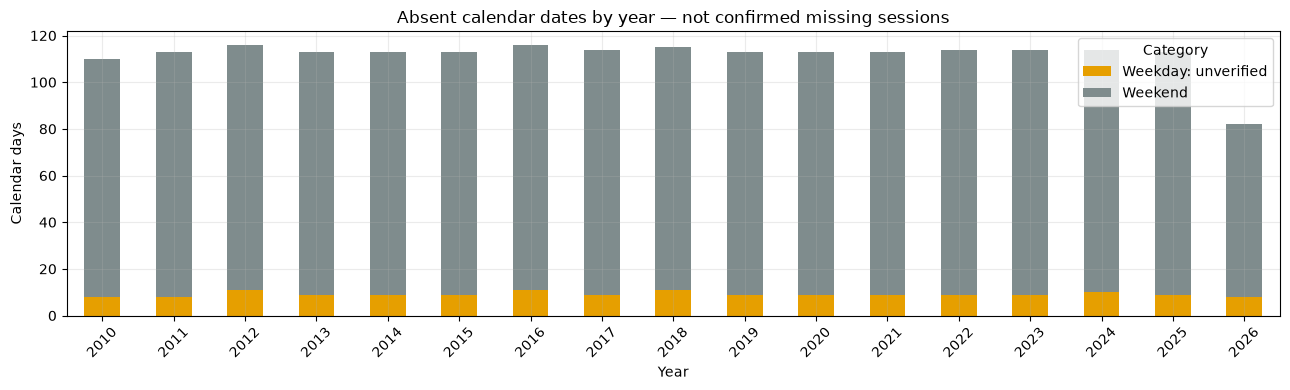


Vị trí các ngày thường vắng: dùng để rà soát xem có tập trung thành cụm không


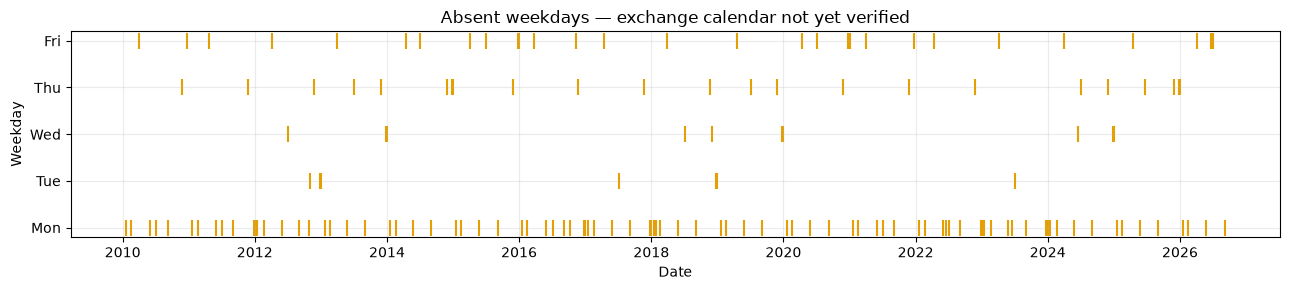


Tối đa 20 ngày thường vắng để đối chiếu (danh sách đầy đủ nằm trong weekday_gaps)


,Absent_date
4,2010-01-18
13,2010-02-15
26,2010-04-02
45,2010-05-31
56,2010-07-05
75,2010-09-06
98,2010-11-25
107,2010-12-24
116,2011-01-17
127,2011-02-21



10 khoảng cách ngày lớn nhất; vẫn có thể bao gồm cuối tuần/ngày nghỉ


,Date,Previous_date,Gap_calendar_days,Absent_dates_between
712,2012-10-31,2012-10-26,5.0,4.0
10,2010-01-19,2010-01-15,4.0,3.0
29,2010-02-16,2010-02-12,4.0,3.0
62,2010-04-05,2010-04-01,4.0,3.0
102,2010-06-01,2010-05-28,4.0,3.0
126,2010-07-06,2010-07-02,4.0,3.0
170,2010-09-07,2010-09-03,4.0,3.0
247,2010-12-27,2010-12-23,4.0,3.0
262,2011-01-18,2011-01-14,4.0,3.0
286,2011-02-22,2011-02-18,4.0,3.0


In [6]:

quality = pd.DataFrame({
    'Missing_cells': df.isna().sum(),
    'Missing_percent': df.isna().mean() * 100,
    'Parse_failures': pd.Series(parse_failures)
})
print('\nThống kê dữ liệu thiếu và lỗi chuyển đổi kiểu dữ liệu')
display(quality)
print('Duplicate raw rows:', int(raw.duplicated().sum()))
print('Duplicate normalized rows:', int(df.duplicated().sum()))

duplicate_dates = df.loc[df['Date'].notna(), 'Date'].duplicated().sum()
if duplicate_dates > 0:
    print(f'Cảnh báo: Có {duplicate_dates} ngày bị trùng.')
else:
    print('Không có ngày bị trùng.')
print('\nCác dòng có ngày bị trùng')
display(df.loc[df['Date'].notna() & df['Date'].duplicated(keep=False)])


observed_dates = pd.DatetimeIndex(df['Date'].dropna().unique()).sort_values()
if len(observed_dates) == 0:
    print('Không có ngày hợp lệ để kiểm tra độ phủ.')
else:
    calendar = pd.date_range(observed_dates.min(), observed_dates.max(), freq='D')
    absent_dates = calendar.difference(observed_dates)
    gap_table = pd.DataFrame({'Absent_date': absent_dates})
    gap_table['Weekend'] = gap_table['Absent_date'].dt.dayofweek >= 5
    weekday_gaps = gap_table.loc[~gap_table['Weekend']].copy()
    print(f'\nTổng số ngày lịch không có bản ghi: {len(gap_table):,}')
    print(f'Trong đó, ngày cuối tuần: {int(gap_table["Weekend"].sum()):,}')
    print(f'Ngày thứ Hai–thứ Sáu cần đối chiếu lịch nguồn: {len(weekday_gaps):,}')
    print('Các số này chưa phải số phiên bị mất dữ liệu.')

    
    gap_table['Year'] = gap_table['Absent_date'].dt.year
    gap_table['Category'] = gap_table['Weekend'].map({True: 'Weekend', False: 'Weekday: unverified'})
    yearly_gaps = pd.crosstab(gap_table['Year'], gap_table['Category'])
    if not yearly_gaps.empty:
        print('\nBiểu đồ số ngày lịch vắng theo năm; năm đầu/cuối có thể chưa đủ năm')
        yearly_gaps.plot.bar(stacked=True, figsize=(13, 4), color=['#e69f00', '#7f8c8d'])
        plt.title('Absent calendar dates by year — not confirmed missing sessions')
        plt.xlabel('Year')
        plt.ylabel('Calendar days')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

    if weekday_gaps.empty:
        print('Không có ngày thứ Hai–thứ Sáu vắng trong phạm vi dữ liệu.')
    else:
        print('\nVị trí các ngày thường vắng: dùng để rà soát xem có tập trung thành cụm không')
        fig, ax = plt.subplots(figsize=(13, 3))
        ax.scatter(weekday_gaps['Absent_date'], weekday_gaps['Absent_date'].dt.dayofweek,
                   color='#e69f00', marker='|', s=130)
        ax.set_yticks([0, 1, 2, 3, 4], ['Mon', 'Tue', 'Wed', 'Thu', 'Fri'])
        ax.set(title='Absent weekdays — exchange calendar not yet verified', xlabel='Date', ylabel='Weekday')
        plt.tight_layout()
        plt.show()
        print('\nTối đa 20 ngày thường vắng để đối chiếu (danh sách đầy đủ nằm trong weekday_gaps)')
        display(weekday_gaps[['Absent_date']].head(20))

    
    consecutive_gaps = pd.Series(observed_dates).to_frame('Date')
    consecutive_gaps['Previous_date'] = consecutive_gaps['Date'].shift(1)
    consecutive_gaps['Gap_calendar_days'] = consecutive_gaps['Date'].diff().dt.days
    consecutive_gaps['Absent_dates_between'] = consecutive_gaps['Gap_calendar_days'] - 1
    long_gaps = consecutive_gaps.loc[consecutive_gaps['Gap_calendar_days'] > 1]
    if not long_gaps.empty:
        print('\n10 khoảng cách ngày lớn nhất; vẫn có thể bao gồm cuối tuần/ngày nghỉ')
        display(long_gaps.nlargest(10, 'Gap_calendar_days'))

### 1.6 Giá trị bất thường và tính hợp lệ

**Hai loại kiểm tra khác nhau:**

- **Domain / OHLC:** kiểm tra tính nhất quán của giá và Volume. Cờ Close ngoài [Low, High] cần xác minh ngữ nghĩa Close/settlement; chưa khẳng định giá sai.
- **IQR:** tìm giá trị xa phân phối chung để rà soát. Q1 và Q3 là phân vị 25% và 75%; IQR = Q3 − Q1. Điểm ngoài [Q1 − 1.5×IQR, Q3 + 1.5×IQR] được tô cam. Đây là quy tắc mô tả, không phải quy tắc xóa dữ liệu.

**Thống kê và biểu đồ:** từng biến gốc có đường thời gian màu xanh, điểm vượt hàng rào IQR màu cam và hai đường ngưỡng nét đứt. Dòng chữ trước hình cho biết số điểm bị flag và khoảng ngày của chúng.

**Diễn giải:** một cụm cam kéo dài ở cuối chuỗi giá có thể phản ánh trend/mặt bằng giá mới. Một điểm cam đứng riêng cần xem thêm các phiên lân cận. Với Volume, thay đổi quy mô có thể làm IQR toàn kỳ kém phù hợp. Cả hai trường hợp đều cần đối chiếu nguồn để kết luận sai hay đúng; không thể xác định chỉ bằng màu trên hình.

IQR toàn kỳ **không xét thứ tự thời gian**, nên ở Part 1 chỉ dùng làm minh họa hạn chế của cách phát hiện outlier trên raw level. Chưa chọn ngưỡng modeling hoặc thực hiện cleaning.

**Vì sao vẫn kiểm tra Yahoo Finance?** Nguồn phổ biến không bảo đảm mọi bản ghi hay mọi bước thu thập đều chính xác. Tài liệu [Price Repair của yfinance](https://ranaroussi.github.io/yfinance/advanced/price_repair.html) mô tả các trường hợp giá thiếu, lỗi đơn vị 100 lần và lỗi điều chỉnh. Đó là lý do kiểm tra chất lượng, không phải bằng chứng rằng file Gold này mắc các lỗi đó. Không bật repair hoặc sửa dữ liệu tự động ở đây.



Số dòng được gắn cờ theo từng kiểm tra chất lượng


,Flagged_rows
Invalid_date,0
Nonfinite_or_missing_numeric,0
High_below_Low,0
Open_outside_range,0
Close_outside_range,25
Nonpositive_price_review,0
Negative_volume,0
Zero_volume_review,40



Chi tiết các dòng được gắn cờ cần xem xét


,Date,Close,High,Low,Open,Volume,Invalid_date,Nonfinite_or_missing_numeric,High_below_Low,Open_outside_range,Close_outside_range,Nonpositive_price_review,Negative_volume,Zero_volume_review
209,2010-11-01,1350.199951,1360.300049,1350.699951,1360.300049,40,False,False,False,False,True,False,False,False
223,2010-11-19,1352.199951,1352.000000,1344.500000,1350.699951,7,False,False,False,False,True,False,False,False
226,2010-11-24,1372.900024,1377.800049,1377.800049,1377.800049,3,False,False,False,False,True,False,False,False
227,2010-11-26,1362.300049,1372.099976,1372.099976,1372.099976,138416,False,False,False,False,True,False,False,False
249,2010-12-29,1413.099976,1412.199951,1402.900024,1403.400024,413,False,False,False,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3898,2025-07-04,3346.500000,3355.000000,3332.800049,3335.000000,0,False,False,False,False,False,False,False,True
3938,2025-08-29,3516.100098,3518.500000,3463.000000,3477.199951,0,False,False,False,False,False,False,False,True
3983,2025-11-03,4014.000000,4043.100098,3971.300049,4001.000000,0,False,False,False,False,False,False,False,True
4086,2026-04-02,4679.700195,4825.899902,4580.399902,4783.000000,0,False,False,False,False,False,False,False,True



Open — điểm ngoài hàng rào IQR theo thời gian
413/4,203 điểm hữu hạn bị flag (9.83%).
Hàng rào dưới: 367.30; hàng rào trên: 2,785.30.
Ngày bị flag đầu/cuối: 2024-10-30 đến 2026-09-18.
Khoảng ngày trên không có nghĩa mọi ngày ở giữa đều bị flag.


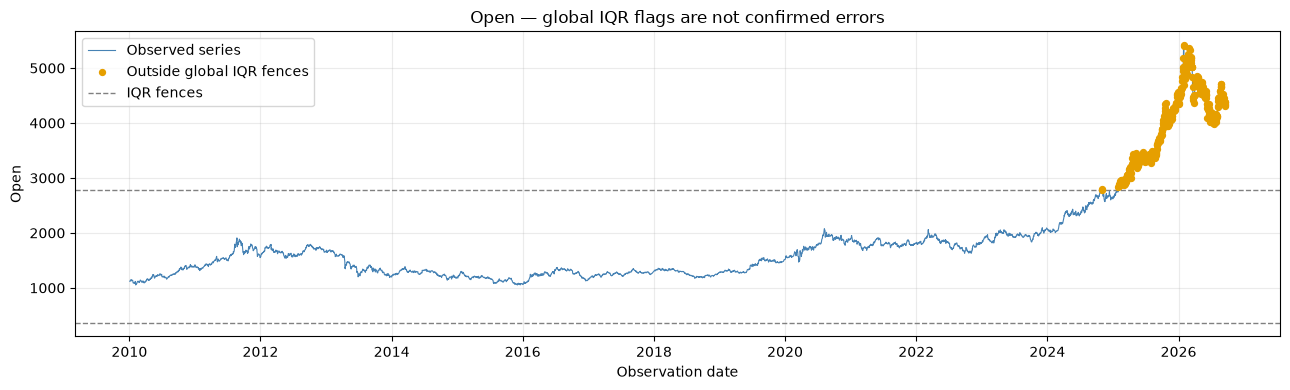


High — điểm ngoài hàng rào IQR theo thời gian
412/4,203 điểm hữu hạn bị flag (9.80%).
Hàng rào dưới: 356.25; hàng rào trên: 2,817.45.
Ngày bị flag đầu/cuối: 2025-01-30 đến 2026-09-18.
Khoảng ngày trên không có nghĩa mọi ngày ở giữa đều bị flag.


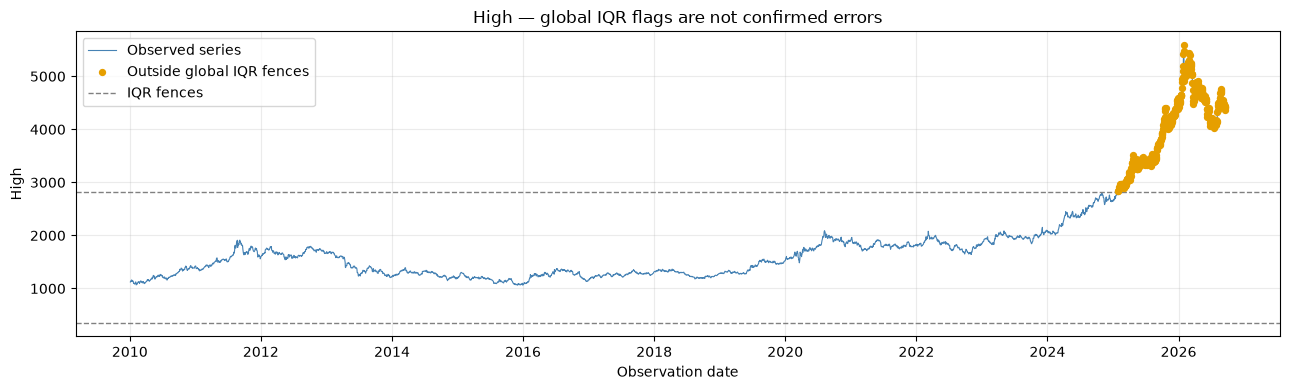


Low — điểm ngoài hàng rào IQR theo thời gian
415/4,203 điểm hữu hạn bị flag (9.87%).
Hàng rào dưới: 376.10; hàng rào trên: 2,757.70.
Ngày bị flag đầu/cuối: 2024-10-30 đến 2026-09-18.
Khoảng ngày trên không có nghĩa mọi ngày ở giữa đều bị flag.


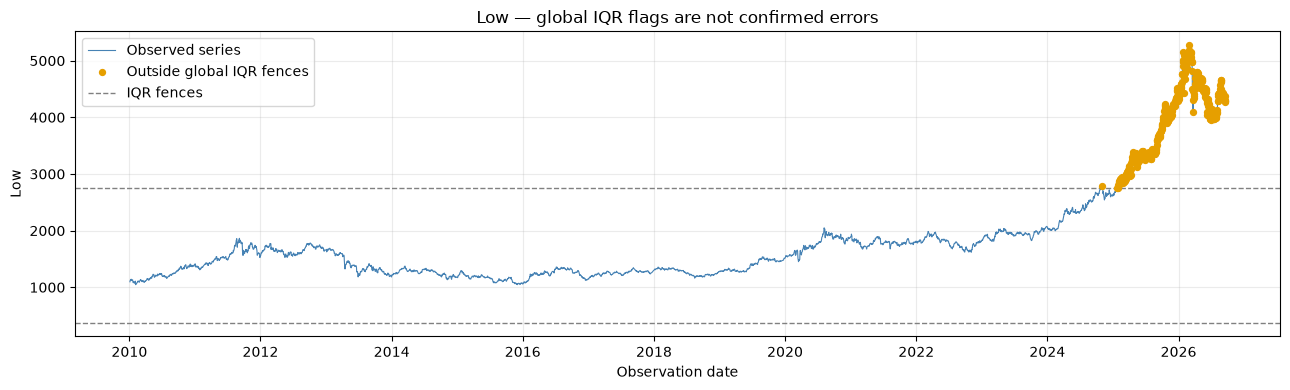


Close — điểm ngoài hàng rào IQR theo thời gian
413/4,203 điểm hữu hạn bị flag (9.83%).
Hàng rào dưới: 365.75; hàng rào trên: 2,786.55.
Ngày bị flag đầu/cuối: 2024-10-30 đến 2026-09-18.
Khoảng ngày trên không có nghĩa mọi ngày ở giữa đều bị flag.


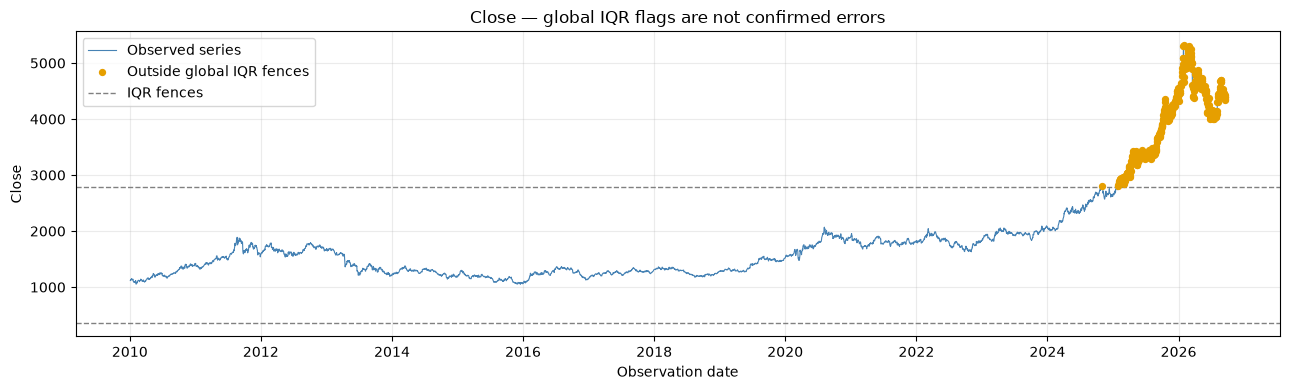


Volume — điểm ngoài hàng rào IQR theo thời gian
20/4,203 điểm hữu hạn bị flag (0.48%).
Hàng rào dưới: -251,462.75; hàng rào trên: 419,315.25.
Ngày bị flag đầu/cuối: 2020-07-27 đến 2026-01-30.
Khoảng ngày trên không có nghĩa mọi ngày ở giữa đều bị flag.


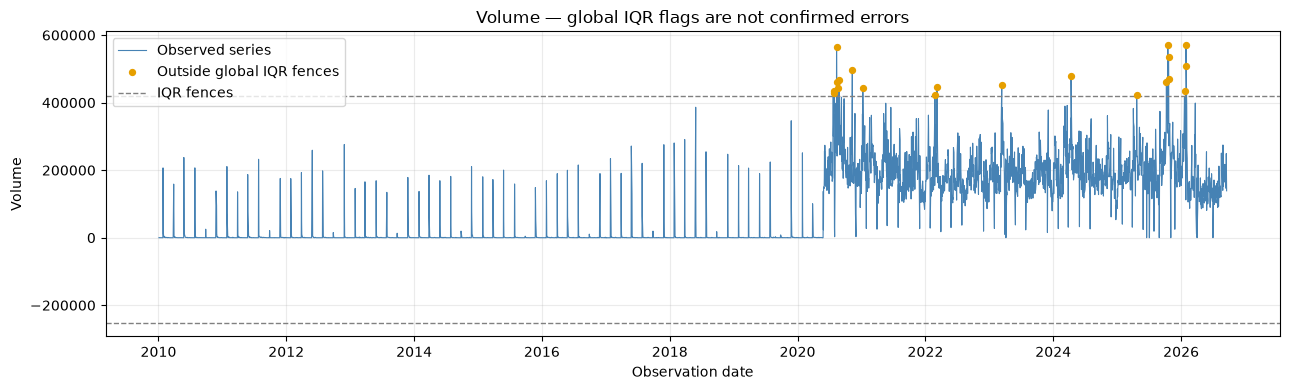

In [7]:

flags = pd.DataFrame(index=df.index)
flags['Invalid_date'] = df['Date'].isna()
flags['Nonfinite_or_missing_numeric'] = df[RAW_NUMERIC].isna().any(axis=1) | df[RAW_NUMERIC].isin([float('inf'), -float('inf')]).any(axis=1)

flags['High_below_Low'] = df['High'] < df['Low']
flags['Open_outside_range'] = (df['Open'] < df['Low']) | (df['Open'] > df['High'])
flags['Close_outside_range'] = (df['Close'] < df['Low']) | (df['Close'] > df['High'])

flags['Nonpositive_price_review'] = (df[['Open','High','Low','Close']] <= 0).any(axis=1)
flags['Negative_volume'] = df['Volume'] < 0
flags['Zero_volume_review'] = df['Volume'] == 0
print('\nSố dòng được gắn cờ theo từng kiểm tra chất lượng')
display(flags.sum().rename('Flagged_rows').to_frame())

flagged_rows = df.loc[flags.any(axis=1)].join(flags.loc[flags.any(axis=1)])
print('\nChi tiết các dòng được gắn cờ cần xem xét')
display(flagged_rows)


iqr_flags = pd.DataFrame(index=df.index)

for column in RAW_NUMERIC:
    values = df[column].replace([float('inf'), -float('inf')], float('nan'))
    valid_values = values.dropna()
    if valid_values.empty:
        print(f'\n{column}: không có giá trị hữu hạn để kiểm tra IQR.')
        continue

    
    q1 = valid_values.quantile(0.25)
    q3 = valid_values.quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    
    outside_iqr = values.notna() & ((values < lower_fence) | (values > upper_fence))
    iqr_flags[column] = outside_iqr
    flagged_count = int(outside_iqr.sum())
    flagged_percent = 100 * flagged_count / len(valid_values)

    print(f'\n{column} — điểm ngoài hàng rào IQR theo thời gian')
    print(f'{flagged_count:,}/{len(valid_values):,} điểm hữu hạn bị flag ({flagged_percent:.2f}%).')
    print(f'Hàng rào dưới: {lower_fence:,.2f}; hàng rào trên: {upper_fence:,.2f}.')
    if iqr == 0:
        print('Lưu ý: IQR = 0, quy tắc này có thể flag nhiều điểm chỉ vì dữ liệu tập trung tại một mức.')
    if flagged_count > 0:
        flagged_dates = df.loc[outside_iqr, 'Date']
        print(f'Ngày bị flag đầu/cuối: {flagged_dates.min():%Y-%m-%d} đến {flagged_dates.max():%Y-%m-%d}.')
        print('Khoảng ngày trên không có nghĩa mọi ngày ở giữa đều bị flag.')
    else:
        print('Không có điểm ngoài hàng rào IQR; điều này không chứng minh dữ liệu hoàn toàn đúng.')

    
    fig, ax = plt.subplots(figsize=(13, 4))
    ax.plot(df['Date'], values, color='steelblue', linewidth=0.8, label='Observed series')
    ax.scatter(df.loc[outside_iqr, 'Date'], values.loc[outside_iqr],
               color='#e69f00', s=18, zorder=3, label='Outside global IQR fences')
    ax.axhline(lower_fence, color='gray', linestyle='--', linewidth=1, label='IQR fences')
    ax.axhline(upper_fence, color='gray', linestyle='--', linewidth=1)
    ax.set_title(column + ' — global IQR flags are not confirmed errors')
    ax.set_xlabel('Observation date')
    ax.set_ylabel(column)
    ax.legend()
    plt.tight_layout()
    plt.show()

### 1.7 Thống kê mô tả các biến gốc

Mean, median, sample standard deviation (ddof=1), min, max và quartiles. NaN/inf không tham gia thống kê hữu hạn; đã được báo riêng ở kiểm tra chất lượng.


In [8]:

raw_finite = df[RAW_NUMERIC].replace([float('inf'), -float('inf')], float('nan'))

descriptive = raw_finite.describe(percentiles=[.25, .5, .75]).T
descriptive = descriptive.rename(columns={'50%': 'median'})
print('\nThống kê mô tả các biến gốc')
display(descriptive[['count','mean','median','std','min','25%','75%','max']])


Thống kê mô tả các biến gốc


,count,mean,median,std,min,25%,75%,max
Open,4203.0,1791.532049,1558.300049,827.065817,1052.199951,1274.049988,1878.549988,5415.700195
High,4203.0,1804.344658,1568.800049,839.781704,1062.000000,1279.199951,1894.500000,5586.200195
Low,4203.0,1778.121960,1548.599976,814.121051,1045.199951,1269.199951,1864.599976,5272.899902
Close,4203.0,1791.623531,1558.300049,827.557624,1050.800049,1273.549988,1878.750000,5318.399902
Volume,4203.0,77872.176541,591.000000,105593.356631,0.000000,79.000000,167773.500000,570055.000000


### 1.8 Phân phối các biến gốc

Mỗi biến có histogram và boxplot riêng. Giữ toàn bộ giá trị hữu hạn, không cắt đuôi hoặc winsorize. Đây chưa phải phân phối return.


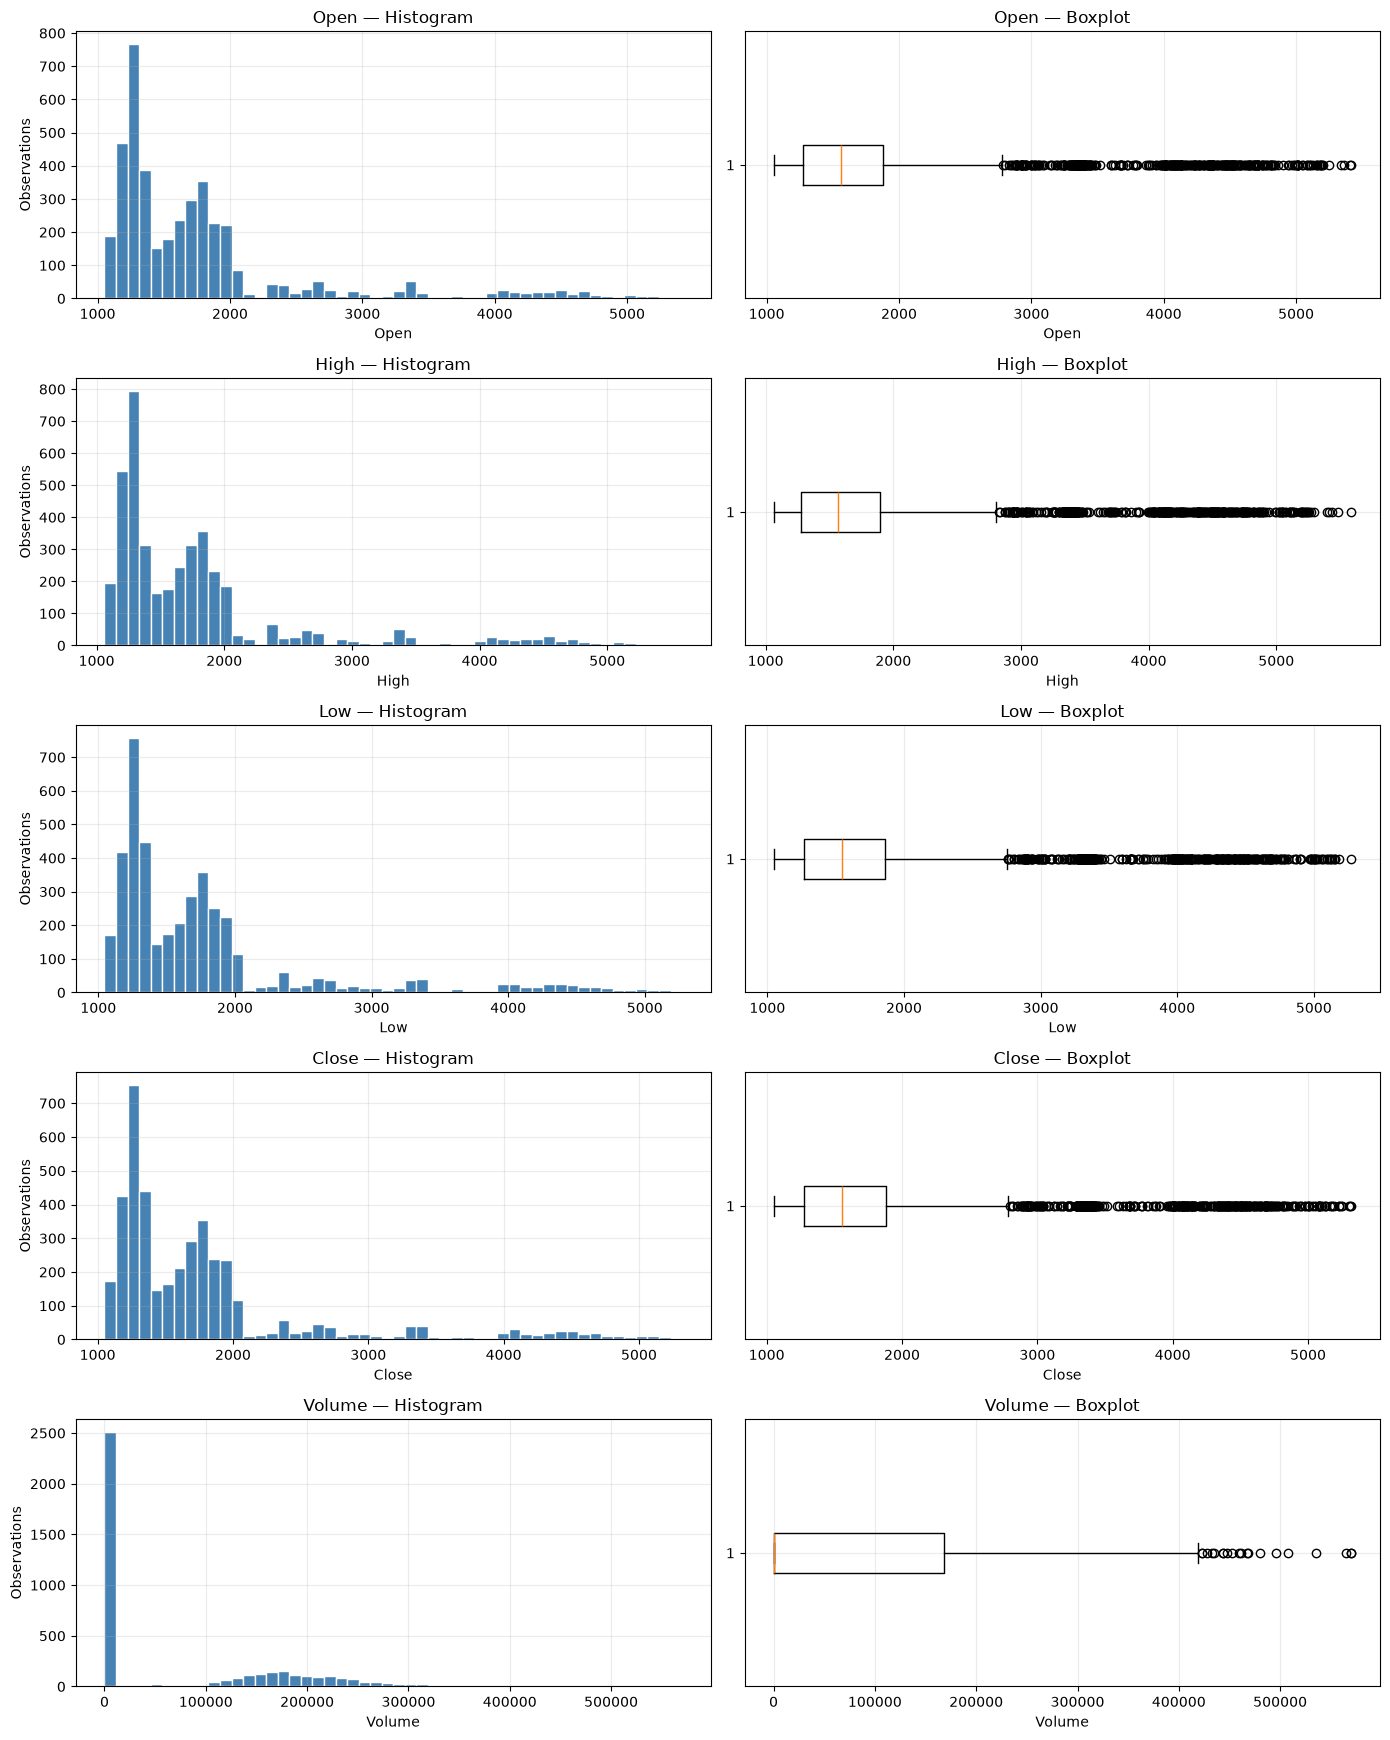

In [9]:

fig, axes = plt.subplots(len(RAW_NUMERIC), 2, figsize=(14, 3.5 * len(RAW_NUMERIC)), squeeze=False)
for row, column in enumerate(RAW_NUMERIC):
    values = raw_finite[column].dropna()
    if len(values):
        
        axes[row, 0].hist(values, bins=50, color='steelblue', edgecolor='white')
        axes[row, 1].boxplot(values, orientation='horizontal')
    axes[row, 0].set_title(column + ' — Histogram')
    axes[row, 0].set_xlabel(column)
    axes[row, 0].set_ylabel('Observations')
    axes[row, 1].set_title(column + ' — Boxplot')
    axes[row, 1].set_xlabel(column)
plt.tight_layout()
plt.show()

### 1.9 Diễn biến theo thời gian

Vẽ từng biến gốc riêng, giữ đơn vị riêng. Bảng theo năm hỗ trợ quan sát thay đổi quy mô. Một bước nhảy trên biểu đồ chỉ là candidate shock/structural break; cần xác minh trước khi gán nguyên nhân.


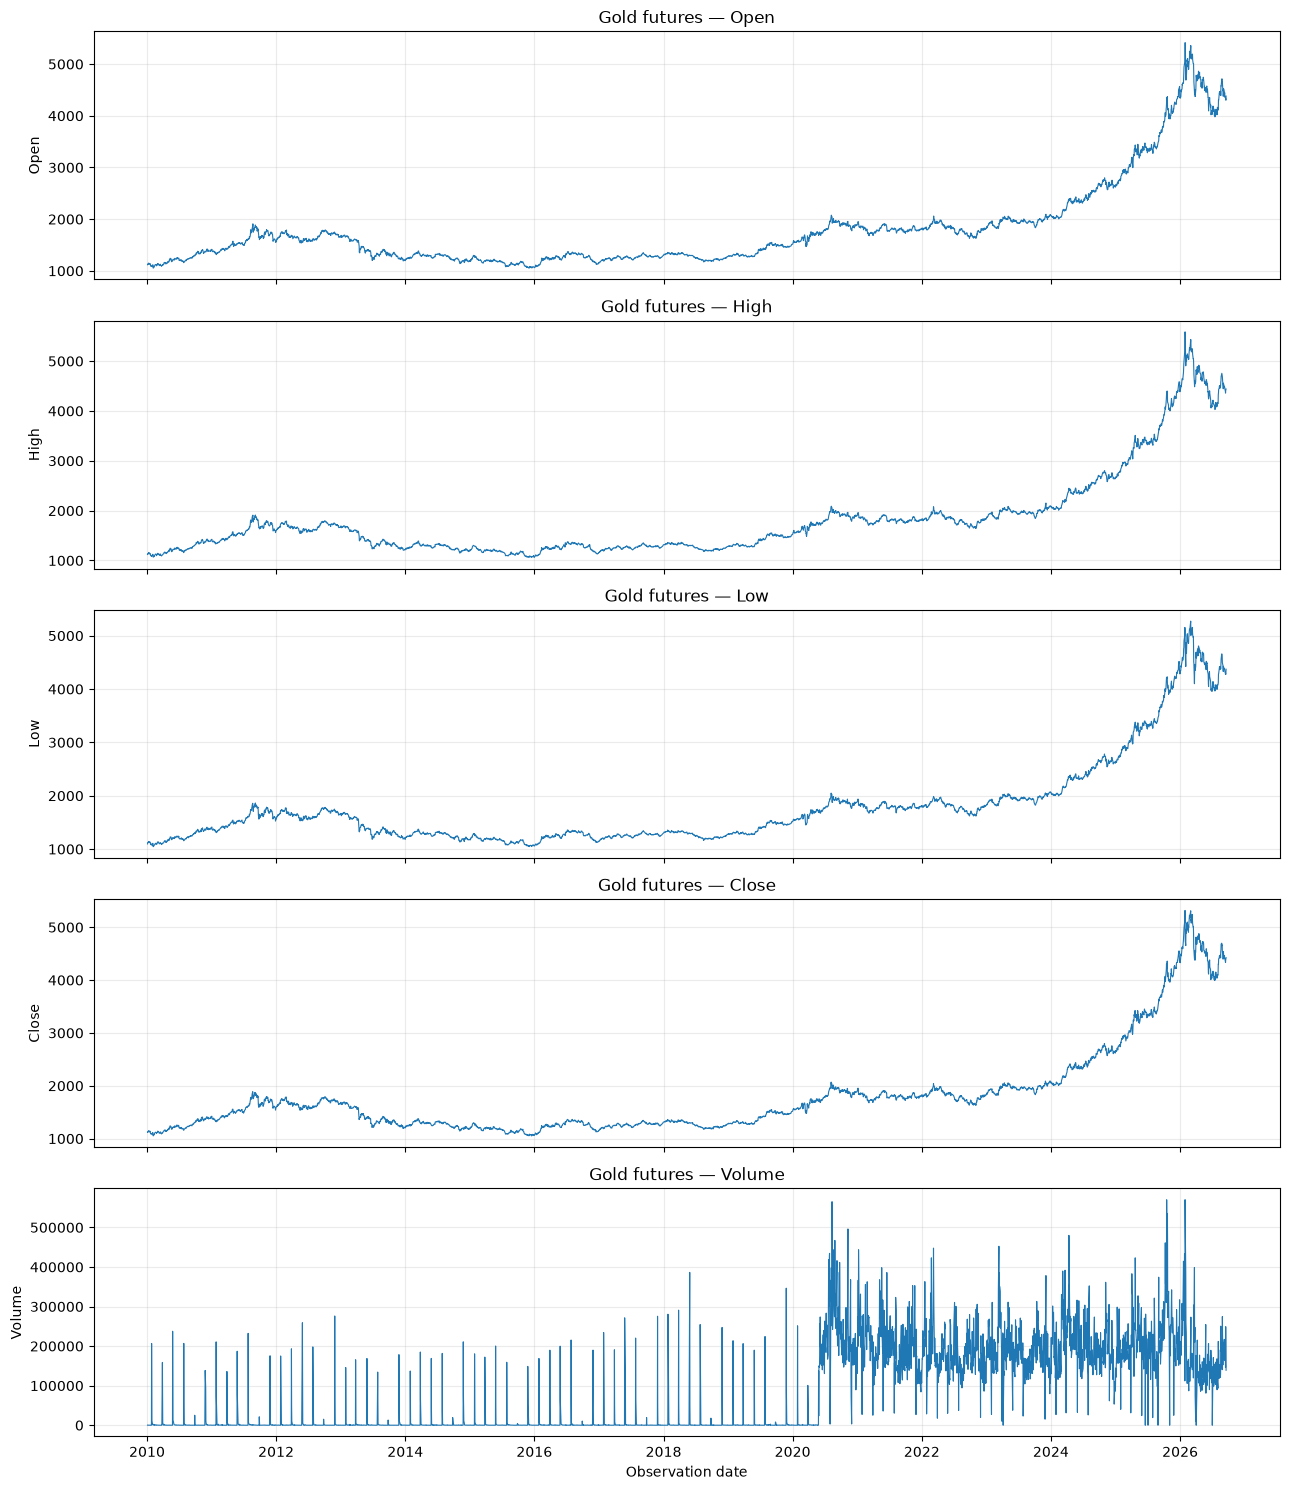


Thống kê các biến gốc theo năm


Open                                                                  \
     count         mean       median         std          min          max   
Date                                                                         
2010   252  1227.182542  1213.300049   98.465721  1052.199951  1424.500000   
2011   252  1572.874604  1544.599976  148.481680  1314.000000  1909.000000   
2012   250  1668.656400  1662.400024   64.455807  1538.199951  1792.199951   
2013   252  1410.805951  1371.750000  146.850177  1190.900024  1691.300049   
2014   252  1265.598017  1273.400024   51.018919  1139.900024  1386.099976   
2015   252  1159.474601  1167.750000   56.660999  1053.699951  1299.800049   
2016   250  1249.329203  1256.549988   72.825780  1063.400024  1371.699951   
2017   251  1257.385256  1260.199951   34.060871  1155.199951  1351.000000   
2018   250  1267.770800  1261.500000   53.915759  1173.199951  1356.300049   
2019   252  1392.624999  1406.500000   92.950648  1266.400024  1551.000000   
2020   253  1776.840319  1785.000000  142.558917  1469.300049  2076.399902   
2021   252  1799.638095  1794.250000   49.834765  1679.300049  1952.800049   
2022   251  1805.825498  1808.199951   91.471773  1629.199951  2060.199951   
2023   251  1954.390835  1958.599976   59.878430  1818.000000  2094.399902   
2024   252  2403.928174  2392.750000  227.700386  2004.800049  2799.100098   
2025   252  3461.854767  3364.849976  486.657923  2641.000000  4568.000000   
2026   179  4578.369269  4544.200195  346.898326  3980.100098  5415.700195   

      High                                        ...        Close  \
     count         mean       median         std  ...       median   
Date                                              ...                
2010   252  1233.158332  1217.950012   99.667238  ...  1213.800049   
2011   252  1583.586908  1552.250000  152.427133  ...  1544.650024   
2012   250  1676.407199  1669.900024   63.716529  ...  1663.549988   
2013   252  1419.240479  1384.400024  145.630175  ...  1371.449951   
2014   252  1271.597221  1277.450012   50.406563  ...  1273.649963   
2015   252  1165.493253  1172.950012   57.299240  ...  1166.700012   
2016   250  1256.944398  1264.200012   72.826626  ...  1257.049988   
2017   251  1261.780877  1266.000000   33.785957  ...  1259.599976   
2018   250  1271.430001  1267.849976   54.614391  ...  1264.599976   
2019   252  1397.523415  1413.500000   94.644477  ...  1408.799988   
2020   253  1791.666404  1799.000000  144.039944  ...  1782.000000   
2021   252  1811.103968  1805.350037   49.269420  ...  1794.299988   
2022   251  1818.913151  1819.699951   92.138950  ...  1809.599976   
2023   251  1967.352990  1972.800049   60.823295  ...  1960.400024   
2024   252  2421.606346  2408.650024  229.143795  ...  2393.799927   
2025   252  3495.501585  3394.349976  495.726419  ...  3361.849976   
2026   179  4641.415072  4597.100098  357.959503  ...  4545.299805   

                                           Volume                           \
             std          min          max  count           mean    median   
Date                                                                         
2010   98.812877  1052.199951  1421.099976    252    6054.523810     137.5   
2011  147.469385  1318.400024  1888.699951    252    5748.904762     198.5   
2012   63.734302  1536.199951  1794.099976    250    6072.788000      86.0   
2013  146.505498  1195.000000  1692.800049    252    4703.289683     130.0   
2014   50.762294  1142.300049  1379.000000    252    5017.738095     141.0   
2015   57.063959  1050.800049  1300.699951    252    4819.460317     138.0   
2016   72.472837  1073.900024  1364.900024    250    5413.364000     194.5   
2017   34.196701  1160.400024  1346.000000    251    6539.346614     116.0   
2018   54.144082  1176.199951  1362.400024    250    7281.440000      56.5   
2019   92.909212  1269.300049  1550.300049    252    6489.920635     116.5   
2020  142.656486  1477.300049 

In [10]:

fig, axes = plt.subplots(len(RAW_NUMERIC), 1, figsize=(13, 3 * len(RAW_NUMERIC)), squeeze=False, sharex=True)
for row, column in enumerate(RAW_NUMERIC):
    axes[row, 0].plot(df['Date'], raw_finite[column], linewidth=.8)
    axes[row, 0].set_title(TITLE + ' — ' + column)
    axes[row, 0].set_ylabel(column)
axes[-1, 0].set_xlabel('Observation date')
plt.tight_layout()
plt.show()

annual_raw = raw_finite.groupby(df['Date'].dt.year).agg(['count','mean','median','std','min','max'])
print('\nThống kê các biến gốc theo năm')
display(annual_raw)

**Điểm cần chú ý riêng:** OHLC có thể không nhất quán nếu Close mang ngữ nghĩa settlement khác với intraday range. Volume futures có thể thay đổi cấu trúc; cần xác minh trước khi sửa hoặc loại dữ liệu.


## Part 2 — Feature-oriented EDA

Phần này nghiên cứu từng feature của **riêng Gold** theo thứ tự: câu hỏi → đại lượng cần đo → cách tính → bảng/biểu đồ.

Cấu hình EDA: lag **1/2/3/5 phiên**, volatility **5/20/60 phiên**, MA **5/20/50 phiên**, **RSI Wilder 14**, **MACD 12/26/9**. Đây là cấu hình EDA, chưa phải cấu hình tối ưu cho mô hình.

Các phép tính dùng phiên quan sát của Gold, không thêm ngày cuối tuần. Feature tại t dùng dữ liệu đến hết t; điều kiện biết được Close tại thời điểm dự báo vẫn cần xác minh ở stage căn chỉnh thời gian. Chưa tạo target, chia tập, chọn ngưỡng ARM hay merge nguồn khác.

**Đơn vị:** return, range, volatility và MA distance được lưu ở dạng tỷ lệ (0.01 = 1%) nhưng hiển thị theo %. RSI nằm trong [0,100]. MA và MACD dùng USD/troy ounce.



### 2.0 Chuẩn bị dữ liệu và cấu hình

Giữ `df` của Part 1 nguyên vẹn, tạo bản sao `gold`. Kiểm tra điều kiện tính feature bằng thông báo. Nếu Date/Close chưa hợp lệ, các cell tính toán sẽ in lý do bỏ qua thay vì tạo kết quả không đáng tin. OHLC cần kiểm tra riêng ở mục Intraday Range.


In [11]:

gold = df.copy()


LAGS = [1, 2, 3, 5]
VOL_WINDOWS = [5, 20, 60]
MA_WINDOWS = [5, 20, 50]
RSI_WINDOW = 14
MACD_FAST = 12
MACD_SLOW = 26
MACD_SIGNAL = 9


feature_ready = True
if gold.empty:
    print('Cảnh báo: Dữ liệu rỗng; chưa tính feature.')
    feature_ready = False
if gold['Date'].isna().any() or gold['Date'].duplicated().any():
    print('Cảnh báo: Date thiếu hoặc trùng; cần kiểm tra lại Part 1.')
    feature_ready = False
if not gold['Date'].is_monotonic_increasing:
    print('Cảnh báo: Date chưa tăng dần; cần kiểm tra thứ tự ở Part 1.')
    feature_ready = False
invalid_close = gold['Close'].isna() | gold['Close'].isin([float('inf'), -float('inf')]) | (gold['Close'] <= 0)
if invalid_close.any():
    print(f'Cảnh báo: Có {int(invalid_close.sum())} Close thiếu, không hữu hạn hoặc không dương.')
    feature_ready = False
if feature_ready:
    print(f'Dữ liệu đủ điều kiện tính feature trên {len(gold):,} phiên quan sát.')
    print('Các dòng warm-up sẽ để NaN, không fill bằng 0.')
else:
    print('Các cell feature bên dưới sẽ bỏ qua phép tính cho tới khi đầu vào được xử lý.')


feature_columns = []

Dữ liệu đủ điều kiện tính feature trên 4,203 phiên quan sát.
Các dòng warm-up sẽ để NaN, không fill bằng 0.


### 2.1 Daily Return

**Câu hỏi:** Giá Gold hôm nay thay đổi bao nhiêu so với phiên quan sát trước?

**Ý nghĩa:** Đo biến động tương đối để giảm ảnh hưởng của mặt bằng giá dài hạn.

**Cách tính và đơn vị:** `Daily_Return(t) = Close(t) / Close(t−1) − 1`. Dòng đầu thiếu vì chưa có phiên trước. Không forward-fill.

**Thống kê và biểu đồ:** Bảng thống kê theo %, line chart, histogram/boxplot và 10 phiên có |return| lớn nhất. Các phiên cực trị chỉ được đánh dấu để rà soát, không bị xóa.



Thống kê Daily Return — đơn vị % mỗi phiên


,Return (%)
count,4202.000000
mean,0.038651
std,1.083984
min,-10.779554
1%,-3.022523
25%,-0.466867
50%,0.043480
75%,0.598057
99%,2.847828
max,6.069722


Số dòng thiếu do chưa có phiên trước: 1

10 phiên có độ lớn Daily Return cao nhất


,Date,Close,Return (%)
414,2011-08-24,1754.099976,-5.607279
435,2011-09-23,1637.500000,-5.847513
824,2013-04-15,1360.599976,-9.353766
871,2013-06-20,1285.900024,-6.384679
2568,2020-03-23,1567.000000,5.592992
2569,2020-03-24,1660.199951,5.947668
3974,2025-10-21,4109.100098,-5.741611
4043,2026-01-30,4745.100098,-10.779554
4045,2026-02-03,4935.000000,6.069722
4076,2026-03-19,4605.700195,-5.933172


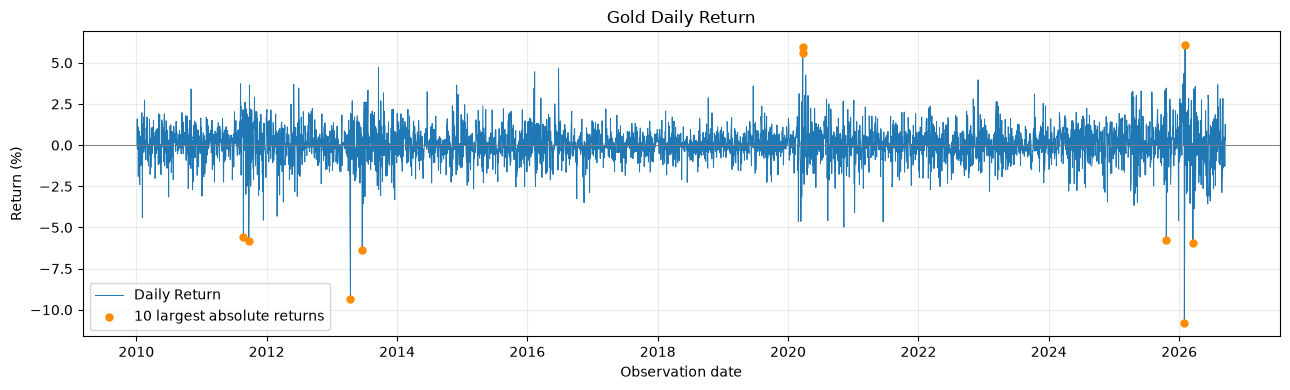

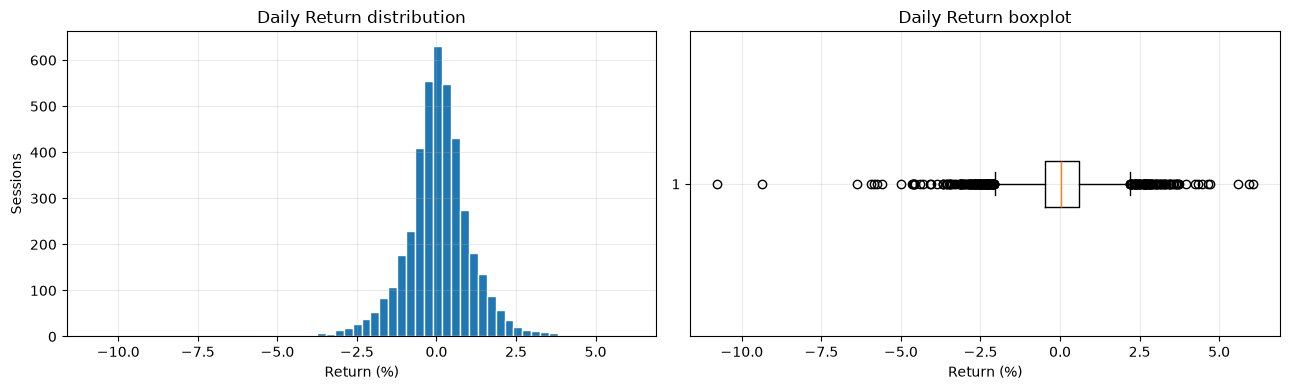

In [12]:
if feature_ready:
    
    gold['Daily_Return'] = gold['Close'].pct_change(fill_method=None)
    feature_columns.append('Daily_Return')
    return_percent = gold['Daily_Return'] * 100

    print('\nThống kê Daily Return — đơn vị % mỗi phiên')
    display(return_percent.describe(percentiles=[.01, .25, .5, .75, .99]).to_frame('Return (%)'))
    print('Số dòng thiếu do chưa có phiên trước:', int(gold['Daily_Return'].isna().sum()))

    
    extreme_rows = gold['Daily_Return'].abs().nlargest(10).index
    extreme_table = gold.loc[extreme_rows, ['Date', 'Close']].copy()
    extreme_table['Return (%)'] = return_percent.loc[extreme_rows]
    print('\n10 phiên có độ lớn Daily Return cao nhất')
    display(extreme_table.sort_values('Date'))

    
    fig, ax = plt.subplots(figsize=(13, 4))
    ax.plot(gold['Date'], return_percent, linewidth=.7, label='Daily Return')
    ax.scatter(gold.loc[extreme_rows, 'Date'], return_percent.loc[extreme_rows],
               color='darkorange', s=25, label='10 largest absolute returns', zorder=3)
    ax.axhline(0, color='gray', linewidth=.7)
    ax.set(title='Gold Daily Return', xlabel='Observation date', ylabel='Return (%)')
    ax.legend()
    plt.tight_layout()
    plt.show()

    
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].hist(return_percent.dropna(), bins=60, edgecolor='white')
    axes[0].set(title='Daily Return distribution', xlabel='Return (%)', ylabel='Sessions')
    axes[1].boxplot(return_percent.dropna(), orientation='horizontal')
    axes[1].set(title='Daily Return boxplot', xlabel='Return (%)')
    plt.tight_layout()
    plt.show()
else:
    print('Chưa tính Daily Return: kiểm tra thông báo ở mục 2.0.')

### 2.2 Lagged Return

**Câu hỏi:** Biến động các phiên trước có đi cùng quán tính hoặc đảo chiều trong chính Gold không?

**Ý nghĩa:** Đặt giả thuyết momentum/reversal từ lịch sử, chưa kiểm tra khả năng dự báo Gold t+1.

**Cách tính và đơn vị:** `Return_Lag_k(t) = Daily_Return(t−k)` bằng `shift(k)`, k = 1,2,3,5 phiên. Đây không phải số ngày lịch.

**Thống kê và biểu đồ:** Bảng mapping ngày hiện tại/ngày nguồn, số cặp hợp lệ, correlation nội chuỗi và scatter từng lag với return hiện tại.



Lag 1 phiên — 8 dòng đầu của mapping ngày nguồn


,Date,Source_date,Lagged Return (%)
0,2010-01-04,NaT,NaN
1,2010-01-05,2010-01-04,NaN
2,2010-01-06,2010-01-05,0.035790
3,2010-01-07,2010-01-06,1.591991
4,2010-01-08,2010-01-07,-0.246505
5,2010-01-11,2010-01-08,0.450091
6,2010-01-12,2010-01-11,1.098225
7,2010-01-13,2010-01-12,-1.894493



Lag 2 phiên — 8 dòng đầu của mapping ngày nguồn


,Date,Source_date,Lagged Return (%)
0,2010-01-04,NaT,NaN
1,2010-01-05,NaT,NaN
2,2010-01-06,2010-01-04,NaN
3,2010-01-07,2010-01-05,0.035790
4,2010-01-08,2010-01-06,1.591991
5,2010-01-11,2010-01-07,-0.246505
6,2010-01-12,2010-01-08,0.450091
7,2010-01-13,2010-01-11,1.098225



Lag 3 phiên — 8 dòng đầu của mapping ngày nguồn


,Date,Source_date,Lagged Return (%)
0,2010-01-04,NaT,NaN
1,2010-01-05,NaT,NaN
2,2010-01-06,NaT,NaN
3,2010-01-07,2010-01-04,NaN
4,2010-01-08,2010-01-05,0.035790
5,2010-01-11,2010-01-06,1.591991
6,2010-01-12,2010-01-07,-0.246505
7,2010-01-13,2010-01-08,0.450091



Lag 5 phiên — 8 dòng đầu của mapping ngày nguồn


,Date,Source_date,Lagged Return (%)
0,2010-01-04,NaT,NaN
1,2010-01-05,NaT,NaN
2,2010-01-06,NaT,NaN
3,2010-01-07,NaT,NaN
4,2010-01-08,NaT,NaN
5,2010-01-11,2010-01-04,NaN
6,2010-01-12,2010-01-05,0.035790
7,2010-01-13,2010-01-06,1.591991


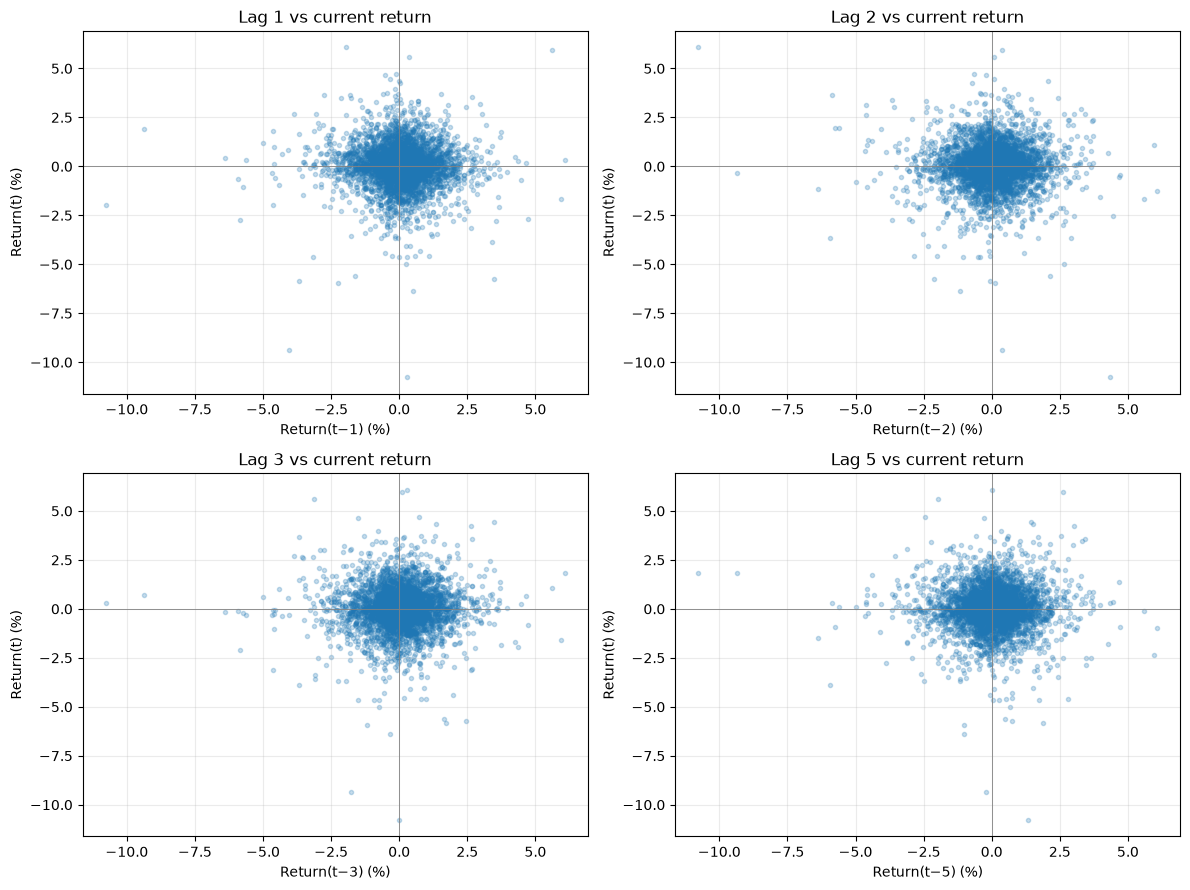


Tóm tắt lag — correlation mô tả toàn kỳ, không dùng để chọn lag


,Lag (sessions),Valid pairs,Missing lag values,Correlation with current return
0,1,4201,2,-0.030269
1,2,4200,3,-0.014179
2,3,4199,4,0.017967
3,5,4197,6,-0.000715


In [13]:
if feature_ready:
    lag_summary = []
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    for lag, ax in zip(LAGS, axes.flat):
        
        column = f'Return_Lag_{lag}'
        gold[column] = gold['Daily_Return'].shift(lag)
        feature_columns.append(column)

        
        mapping = gold[['Date']].copy()
        mapping['Source_date'] = gold['Date'].shift(lag)
        mapping['Lagged Return (%)'] = gold[column] * 100
        print(f'\nLag {lag} phiên — 8 dòng đầu của mapping ngày nguồn')
        display(mapping.head(8))

        
        pair = gold[[column, 'Daily_Return']].dropna()
        lag_summary.append({'Lag (sessions)': lag, 'Valid pairs': len(pair),
                            'Missing lag values': int(gold[column].isna().sum()),
                            'Correlation with current return': pair[column].corr(pair['Daily_Return'])})
        ax.scatter(pair[column] * 100, pair['Daily_Return'] * 100, s=9, alpha=.25)
        ax.axhline(0, color='gray', linewidth=.6)
        ax.axvline(0, color='gray', linewidth=.6)
        ax.set(title=f'Lag {lag} vs current return', xlabel=f'Return(t−{lag}) (%)', ylabel='Return(t) (%)')
    plt.tight_layout()
    plt.show()
    print('\nTóm tắt lag — correlation mô tả toàn kỳ, không dùng để chọn lag')
    display(pd.DataFrame(lag_summary))
else:
    print('Chưa tính Lagged Return: kiểm tra mục 2.0.')

### 2.3 Intraday Range

**Câu hỏi:** Một ngày Close ít thay đổi có vẫn có dao động lớn trong phiên không?

**Ý nghĩa:** Đo biên độ High–Low, bổ sung góc nhìn khác với return giữa hai phiên.

**Cách tính và đơn vị:** `Intraday_Range = (High−Low)/Close`; lưu tỷ lệ, hiển thị %. Không tự sửa các dòng OHLC bất thường.

**Thống kê và biểu đồ:** Line chart với các dòng OHLC cần xem xét được tô màu, histogram range, scatter |return| với range và bảng 10 range lớn nhất.



Thống kê Intraday Range — đơn vị % của Close


,Range (%)
count,4203.000000
mean,1.274821
std,0.970568
min,0.000000
25%,0.689805
50%,1.114272
75%,1.627784
max,16.433801


Dòng OHLC cần đối chiếu: 25
Range thiếu do High/Low không hợp lệ: 0


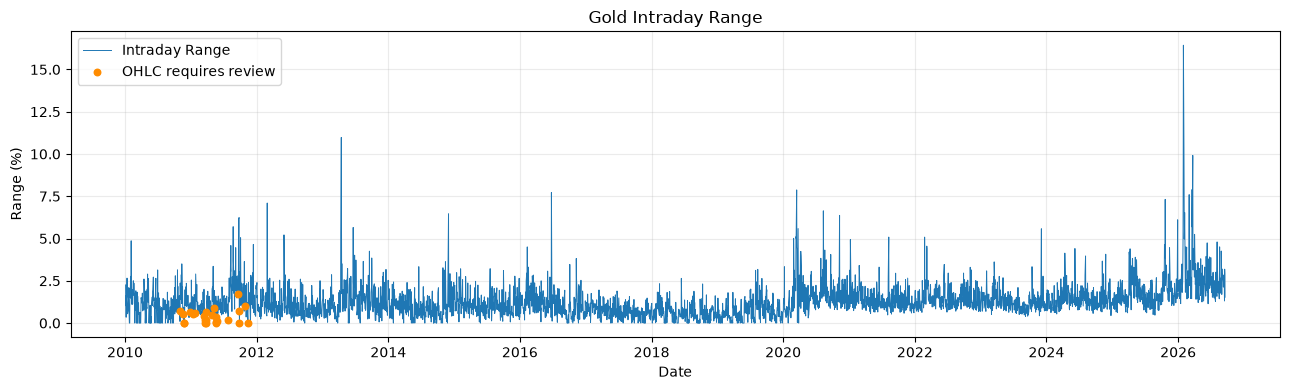

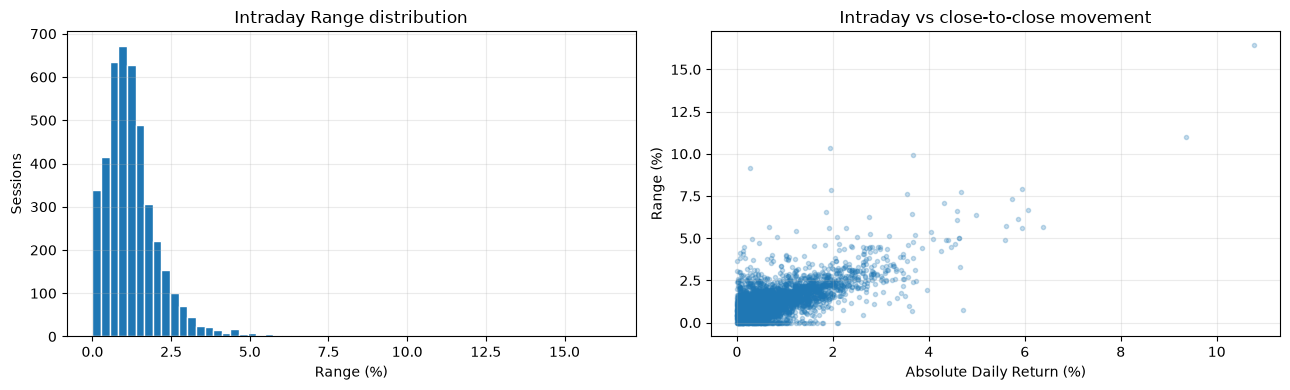


10 phiên có Intraday Range lớn nhất


,Date,Open,High,Low,Close,Range (%),OHLC review
824,2013-04-15,1478.199951,1487.400024,1338.000000,1360.599976,10.980452,False
1630,2016-06-24,1253.699951,1355.599976,1253.699951,1320.000000,7.719699,False
2563,2020-03-16,1569.099976,1569.099976,1452.099976,1485.900024,7.874016,False
3974,2025-10-21,4371.000000,4393.600098,4093.000000,4109.100098,7.315473,False
4042,2026-01-29,5415.700195,5586.200195,5097.500000,5318.399902,9.188858,False
4043,2026-01-30,5410.000000,5480.200195,4700.399902,4745.100098,16.433801,False
4044,2026-02-02,4816.000000,4905.600098,4423.200195,4652.600098,10.368394,False
4064,2026-03-03,5335.700195,5394.200195,5005.000000,5123.700195,7.596077,False
4076,2026-03-19,4828.000000,4868.700195,4505.000000,4605.700195,7.896741,False
4078,2026-03-23,4450.000000,4537.100098,4100.000000,4407.299805,9.917639,False


In [14]:
if feature_ready:
    
    finite_high_low = gold[['High', 'Low']].notna().all(axis=1) & ~gold[['High', 'Low']].isin([float('inf'), -float('inf')]).any(axis=1)
    gold['Intraday_Range'] = ((gold['High'] - gold['Low']) / gold['Close']).where(finite_high_low)
    feature_columns.append('Intraday_Range')

    
    ohlc_review = (gold['High'] < gold['Low']) | (gold['Open'] < gold['Low']) | (gold['Open'] > gold['High']) | (gold['Close'] < gold['Low']) | (gold['Close'] > gold['High'])
    range_percent = gold['Intraday_Range'] * 100
    print('\nThống kê Intraday Range — đơn vị % của Close')
    display(range_percent.describe().to_frame('Range (%)'))
    print('Dòng OHLC cần đối chiếu:', int(ohlc_review.sum()))
    print('Range thiếu do High/Low không hợp lệ:', int(range_percent.isna().sum()))

    fig, ax = plt.subplots(figsize=(13, 4))
    ax.plot(gold['Date'], range_percent, linewidth=.7, label='Intraday Range')
    ax.scatter(gold.loc[ohlc_review, 'Date'], range_percent.loc[ohlc_review],
               color='darkorange', s=22, label='OHLC requires review', zorder=3)
    ax.set(title='Gold Intraday Range', xlabel='Date', ylabel='Range (%)')
    ax.legend()
    plt.tight_layout()
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].hist(range_percent.dropna(), bins=60, edgecolor='white')
    axes[0].set(title='Intraday Range distribution', xlabel='Range (%)', ylabel='Sessions')
    axes[1].scatter(gold['Daily_Return'].abs() * 100, range_percent, s=9, alpha=.25)
    axes[1].set(title='Intraday vs close-to-close movement', xlabel='Absolute Daily Return (%)', ylabel='Range (%)')
    plt.tight_layout()
    plt.show()

    
    range_rows = gold['Intraday_Range'].nlargest(10).index
    range_review = gold.loc[range_rows, ['Date', 'Open', 'High', 'Low', 'Close']].copy()
    range_review['Range (%)'] = range_percent.loc[range_rows]
    range_review['OHLC review'] = ohlc_review.loc[range_rows]
    print('\n10 phiên có Intraday Range lớn nhất')
    display(range_review.sort_values('Date'))
else:
    print('Chưa tính Intraday Range: kiểm tra mục 2.0.')

### 2.4 Rolling Volatility

**Câu hỏi:** Thị trường gần đây đang yên bình hay biến động mạnh?

**Ý nghĩa:** Mô tả trạng thái rủi ro/biến động của Gold qua các horizon khác nhau.

**Cách tính và đơn vị:** Độ lệch chuẩn mẫu (`ddof=1`) của Daily_Return trong 5/20/60 phiên gần nhất, gồm t. `min_periods=window`; không annualize.

**Thống kê và biểu đồ:** Biểu đồ ba đường volatility, thống kê và số dòng warm-up, boxplot để so độ phân tán.



Rolling Volatility — thống kê theo %, chưa annualize


,count,mean,std,min,25%,50%,75%,max
Volatility_5,4198.0,0.940988,0.554852,0.067227,0.572158,0.825695,1.163947,6.614360
Volatility_20,4183.0,1.001230,0.426165,0.319851,0.729443,0.898893,1.146227,3.475231
Volatility_60,4143.0,1.021383,0.357121,0.490182,0.783418,0.932952,1.153357,2.633201


Volatility_5: 5 dòng thiếu do warm-up.
Volatility_20: 20 dòng thiếu do warm-up.
Volatility_60: 60 dòng thiếu do warm-up.


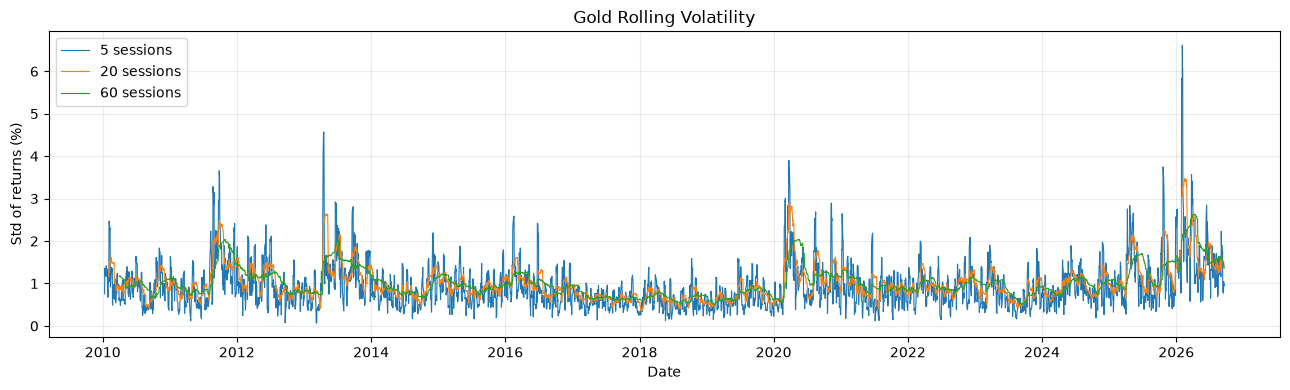

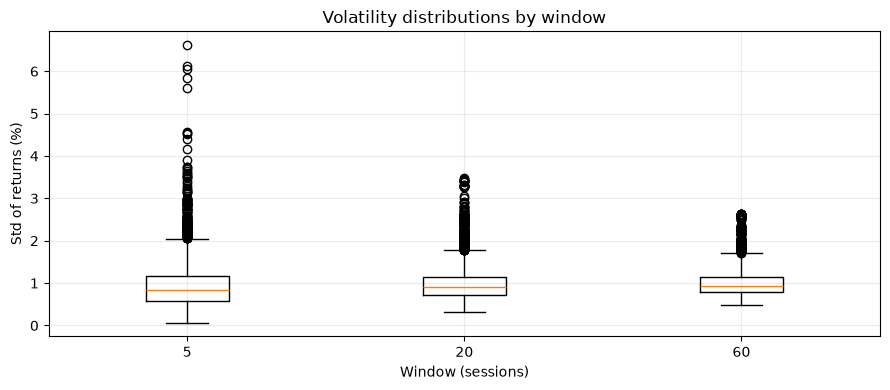

In [15]:
if feature_ready:
    volatility_names = []
    for window in VOL_WINDOWS:
        
        column = f'Volatility_{window}'
        gold[column] = gold['Daily_Return'].rolling(window=window, min_periods=window).std(ddof=1)
        volatility_names.append(column)
        feature_columns.append(column)

    print('\nRolling Volatility — thống kê theo %, chưa annualize')
    display((gold[volatility_names] * 100).describe().T)
    for column in volatility_names:
        print(f'{column}: {int(gold[column].isna().sum())} dòng thiếu do warm-up.')

    fig, ax = plt.subplots(figsize=(13, 4))
    for window, column in zip(VOL_WINDOWS, volatility_names):
        ax.plot(gold['Date'], gold[column] * 100, linewidth=.8, label=f'{window} sessions')
    ax.set(title='Gold Rolling Volatility', xlabel='Date', ylabel='Std of returns (%)')
    ax.legend()
    plt.tight_layout()
    plt.show()

    
    box_values = [(gold[column].dropna() * 100).tolist() for column in volatility_names]
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.boxplot(box_values, tick_labels=[str(w) for w in VOL_WINDOWS])
    ax.set(title='Volatility distributions by window', xlabel='Window (sessions)', ylabel='Std of returns (%)')
    plt.tight_layout()
    plt.show()
else:
    print('Chưa tính Rolling Volatility: kiểm tra mục 2.0.')

### 2.5 Moving Average / Distance to MA

**Câu hỏi:** Giá hiện tại cao hay thấp so với mặt bằng gần đây?

**Ý nghĩa:** MA mô tả trend; khoảng cách tương đối giúp so sánh các thời kỳ có mức giá khác nhau.

**Cách tính và đơn vị:** `MA_w = rolling mean(Close, w)` với w = 5/20/50; `Distance_to_MA_w = Close/MA_w−1`. MA dùng USD/troy ounce, distance dùng tỷ lệ.

**Thống kê và biểu đồ:** Close và MA toàn kỳ, góc nhìn 120 phiên cuối để dễ phân biệt các đường, distance theo thời gian và thống kê theo %. 120 phiên chỉ là phạm vi hiển thị.


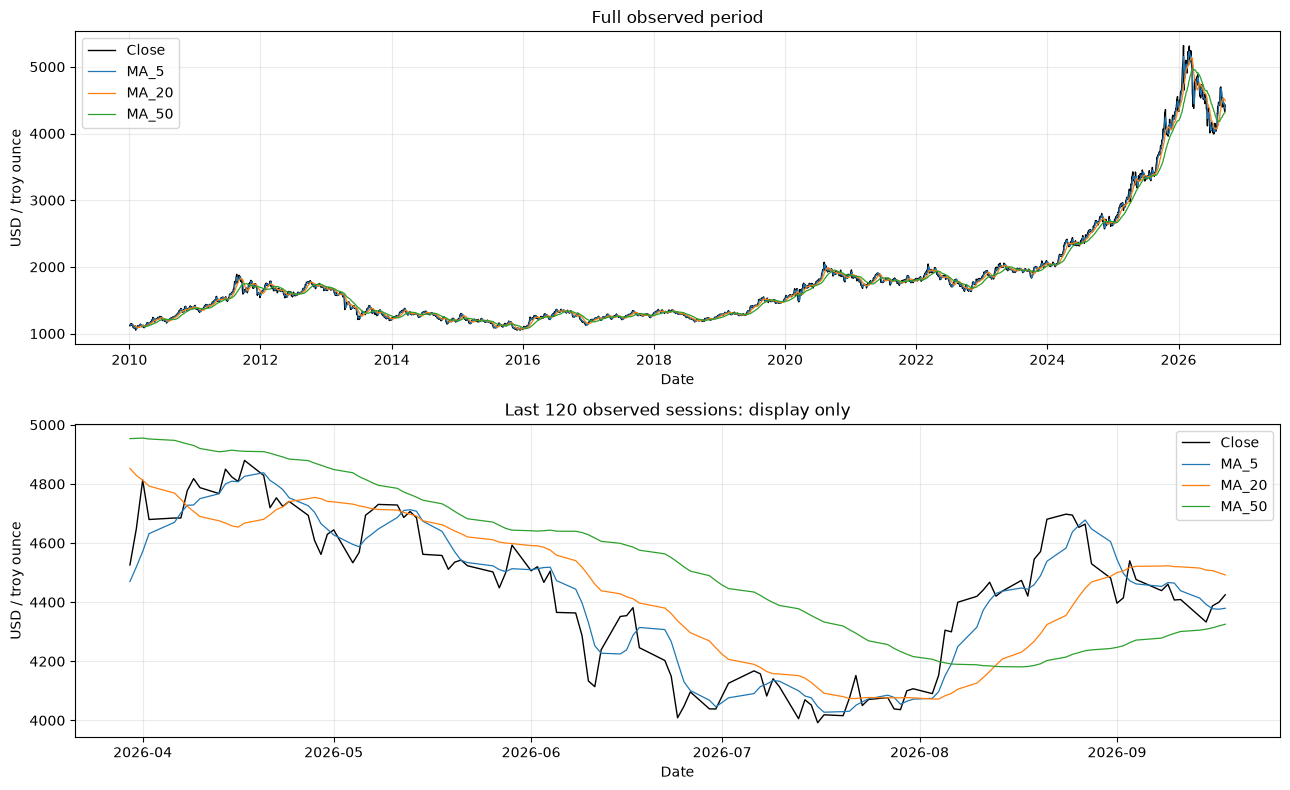

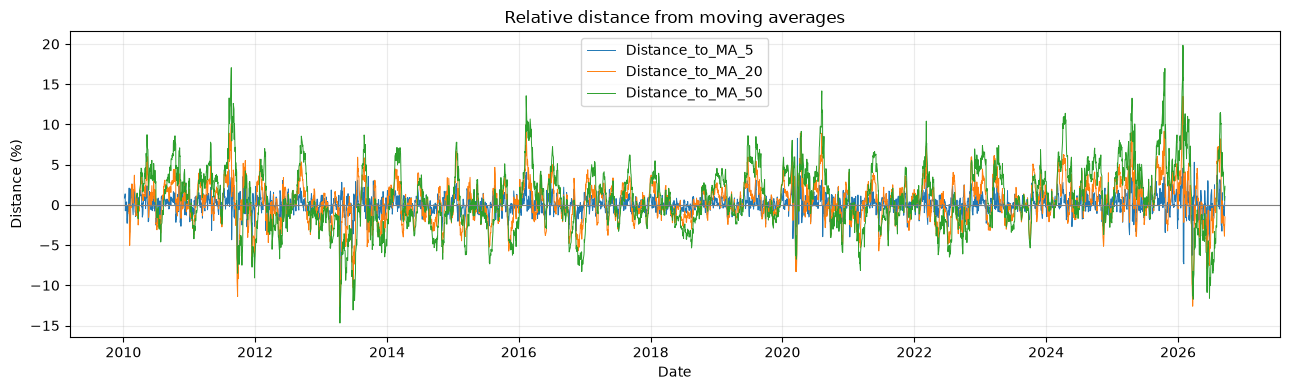


Distance to MA — thống kê theo %


,count,mean,std,min,25%,50%,75%,max
Distance_to_MA_5,4199.0,0.066999,1.162648,-10.136851,-0.544111,0.075447,0.745948,8.267791
Distance_to_MA_20,4184.0,0.329196,2.521007,-13.454170,-1.173014,0.288068,1.897874,13.491630
Distance_to_MA_50,4154.0,0.854282,3.987135,-14.695391,-1.710394,0.552063,3.514117,19.841503



MA — thống kê theo USD/troy ounce


,count,mean,std,min,25%,50%,75%,max
MA_5,4199.0,1790.699309,825.522686,1060.339990,1274.630005,1563.939990,1880.320020,5231.240039
MA_20,4184.0,1787.143081,817.941960,1068.855005,1272.918761,1565.732504,1878.677499,5134.410083
MA_50,4154.0,1780.131519,802.641839,1076.764004,1280.233998,1563.019001,1872.548000,4966.820039


In [16]:
if feature_ready:
    ma_names = []
    distance_names = []
    for window in MA_WINDOWS:
        
        ma_column = f'MA_{window}'
        distance_column = f'Distance_to_MA_{window}'
        gold[ma_column] = gold['Close'].rolling(window=window, min_periods=window).mean()
        gold[distance_column] = gold['Close'] / gold[ma_column] - 1
        ma_names.append(ma_column)
        distance_names.append(distance_column)
        feature_columns.extend([ma_column, distance_column])

    
    fig, axes = plt.subplots(2, 1, figsize=(13, 8))
    for ax, view, label in [(axes[0], gold, 'Full observed period'),
                            (axes[1], gold.tail(120), 'Last 120 observed sessions: display only')]:
        ax.plot(view['Date'], view['Close'], color='black', linewidth=1, label='Close')
        for column in ma_names:
            ax.plot(view['Date'], view[column], linewidth=.9, label=column)
        ax.set(title=label, xlabel='Date', ylabel='USD / troy ounce')
        ax.legend()
    plt.tight_layout()
    plt.show()

    fig, ax = plt.subplots(figsize=(13, 4))
    for column in distance_names:
        ax.plot(gold['Date'], gold[column] * 100, linewidth=.7, label=column)
    ax.axhline(0, color='gray', linewidth=.8)
    ax.set(title='Relative distance from moving averages', xlabel='Date', ylabel='Distance (%)')
    ax.legend()
    plt.tight_layout()
    plt.show()

    print('\nDistance to MA — thống kê theo %')
    display((gold[distance_names] * 100).describe().T)
    print('\nMA — thống kê theo USD/troy ounce')
    display(gold[ma_names].describe().T)
else:
    print('Chưa tính MA và Distance to MA: kiểm tra mục 2.0.')

### 2.6 RSI Wilder 14

**Câu hỏi:** Mức tăng và mức giảm gần đây nghiêng về bên nào?

**Ý nghĩa:** Mô tả momentum trên thang cố định [0,100], khác với level của giá.

**Cách tính và đơn vị:** Gain=max(delta Close,0); Loss=max(−delta Close,0). Seed bằng trung bình 14 delta đầu, sau đó Wilder average=(13×average trước + giá trị mới)/14. RSI=100−100/(1+AvgGain/AvgLoss).

**Thống kê và biểu đồ:** Bảng RSI đầu chuỗi để thấy warm-up, line chart và histogram. Khi AvgLoss=0 và AvgGain>0, RSI=100; cả hai bằng 0 quy ước RSI=50. Không dùng 30/70 làm tín hiệu giao dịch.



20 phiên đầu — kiểm tra warm-up RSI Wilder 14


,Date,Close,RSI_14
0,2010-01-04,1117.699951,NaN
1,2010-01-05,1118.099976,NaN
2,2010-01-06,1135.900024,NaN
3,2010-01-07,1133.099976,NaN
4,2010-01-08,1138.199951,NaN
5,2010-01-11,1150.699951,NaN
6,2010-01-12,1128.900024,NaN
7,2010-01-13,1136.400024,NaN
8,2010-01-14,1142.599976,NaN
9,2010-01-15,1130.099976,NaN



Thống kê RSI Wilder 14


,RSI
count,4189.000000
mean,52.285781
std,12.387684
min,16.555742
25%,44.116933
50%,51.875857
75%,60.768068
max,88.162913


Các giá trị RSI hữu hạn đều nằm trong [0,100].


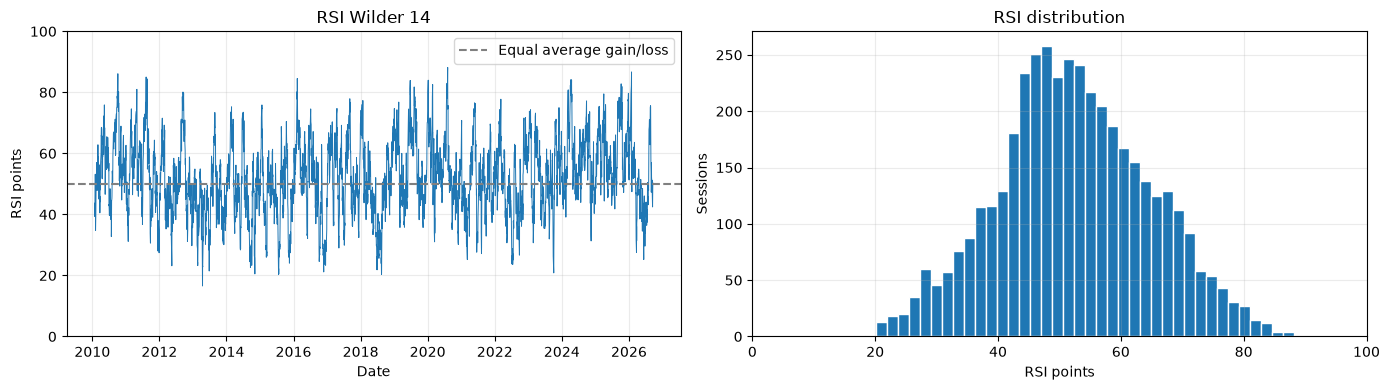

In [17]:
if feature_ready:
    
    price_change = gold['Close'].diff()
    gains = price_change.clip(lower=0)
    losses = -price_change.clip(upper=0)

    
    average_gain = pd.Series(float('nan'), index=gold.index, dtype=float)
    average_loss = pd.Series(float('nan'), index=gold.index, dtype=float)
    if len(gold) > RSI_WINDOW:
        
        average_gain.iloc[RSI_WINDOW] = gains.iloc[1:RSI_WINDOW + 1].mean()
        average_loss.iloc[RSI_WINDOW] = losses.iloc[1:RSI_WINDOW + 1].mean()

        
        for position in range(RSI_WINDOW + 1, len(gold)):
            average_gain.iloc[position] = ((RSI_WINDOW - 1) * average_gain.iloc[position - 1] + gains.iloc[position]) / RSI_WINDOW
            average_loss.iloc[position] = ((RSI_WINDOW - 1) * average_loss.iloc[position - 1] + losses.iloc[position]) / RSI_WINDOW
    else:
        print('Chưa đủ 15 giá Close để có RSI 14 đầu tiên; RSI sẽ để NaN.')

    
    relative_strength = average_gain / average_loss.where(average_loss != 0)
    gold['RSI_14'] = 100 - 100 / (1 + relative_strength)
    gold.loc[(average_loss == 0) & (average_gain > 0), 'RSI_14'] = 100
    gold.loc[(average_loss == 0) & (average_gain == 0), 'RSI_14'] = 50
    feature_columns.append('RSI_14')

    print('\n20 phiên đầu — kiểm tra warm-up RSI Wilder 14')
    display(gold[['Date', 'Close', 'RSI_14']].head(20))
    print('\nThống kê RSI Wilder 14')
    display(gold['RSI_14'].describe().to_frame('RSI'))
    invalid_rsi = (gold['RSI_14'] < 0) | (gold['RSI_14'] > 100)
    if invalid_rsi.any():
        print('Cảnh báo: RSI có giá trị ngoài miền [0,100].')
    else:
        print('Các giá trị RSI hữu hạn đều nằm trong [0,100].')

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(gold['Date'], gold['RSI_14'], linewidth=.7)
    axes[0].axhline(50, color='gray', linestyle='--', label='Equal average gain/loss')
    axes[0].set(title='RSI Wilder 14', xlabel='Date', ylabel='RSI points', ylim=(0, 100))
    axes[0].legend()
    axes[1].hist(gold['RSI_14'].dropna(), bins=40, edgecolor='white')
    axes[1].set(title='RSI distribution', xlabel='RSI points', ylabel='Sessions', xlim=(0, 100))
    plt.tight_layout()
    plt.show()
else:
    print('Chưa tính RSI: kiểm tra mục 2.0.')

### 2.7 MACD 12/26/9

**Câu hỏi:** Xu hướng ngắn hạn khác xu hướng dài hơn như thế nào?

**Ý nghĩa:** Mô tả khoảng cách hai EMA và thay đổi của khoảng cách đó, như một ứng viên momentum/trend.

**Cách tính và đơn vị:** MACD=EMA12(Close)−EMA26(Close); Signal=EMA9(MACD); Histogram=MACD−Signal. `adjust=False`, seed từ quan sát hữu hạn đầu, `min_periods=span`. Đơn vị USD/troy ounce.

**Thống kê và biểu đồ:** Bảng warm-up, thống kê ba thành phần, biểu đồ toàn kỳ và 120 phiên cuối. Histogram MACD là tên một chuỗi chênh lệch, không phải histogram tần suất.



40 phiên đầu — kiểm tra warm-up của MACD và Signal


,Date,MACD,MACD_Signal,MACD_Histogram
0,2010-01-04,NaN,NaN,NaN
1,2010-01-05,NaN,NaN,NaN
2,2010-01-06,NaN,NaN,NaN
3,2010-01-07,NaN,NaN,NaN
4,2010-01-08,NaN,NaN,NaN
5,2010-01-11,NaN,NaN,NaN
6,2010-01-12,NaN,NaN,NaN
7,2010-01-13,NaN,NaN,NaN
8,2010-01-14,NaN,NaN,NaN
9,2010-01-15,NaN,NaN,NaN



Thống kê MACD — đơn vị USD/troy ounce


,count,mean,std,min,25%,50%,75%,max
MACD,4178.0,5.550837,27.359100,-157.221049,-7.194462,2.690584,15.028064,222.705615
MACD_Signal,4170.0,5.550844,25.828461,-114.275819,-6.547787,2.143487,14.950747,166.326210
MACD_Histogram,4170.0,0.024774,8.120791,-96.036948,-3.145498,0.191600,3.521867,62.154433


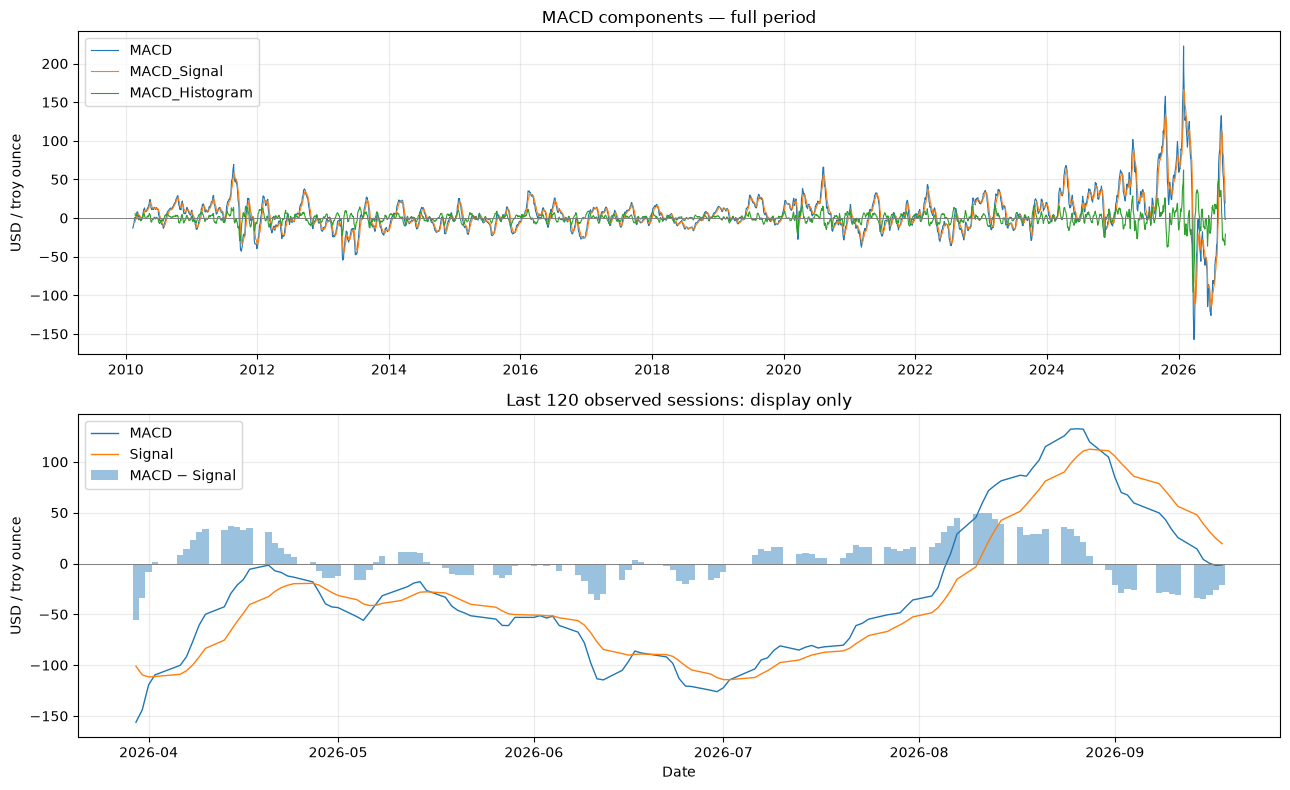

In [18]:
if feature_ready:
    
    ema_fast = gold['Close'].ewm(span=MACD_FAST, adjust=False, min_periods=MACD_FAST).mean()
    ema_slow = gold['Close'].ewm(span=MACD_SLOW, adjust=False, min_periods=MACD_SLOW).mean()
    gold['MACD'] = ema_fast - ema_slow
    gold['MACD_Signal'] = gold['MACD'].ewm(span=MACD_SIGNAL, adjust=False, min_periods=MACD_SIGNAL).mean()
    gold['MACD_Histogram'] = gold['MACD'] - gold['MACD_Signal']
    macd_columns = ['MACD', 'MACD_Signal', 'MACD_Histogram']
    feature_columns.extend(macd_columns)

    print('\n40 phiên đầu — kiểm tra warm-up của MACD và Signal')
    display(gold[['Date'] + macd_columns].head(40))
    print('\nThống kê MACD — đơn vị USD/troy ounce')
    display(gold[macd_columns].describe().T)

    
    fig, axes = plt.subplots(2, 1, figsize=(13, 8))
    for column in macd_columns:
        axes[0].plot(gold['Date'], gold[column], linewidth=.8, label=column)
    axes[0].set(title='MACD components — full period', ylabel='USD / troy ounce')
    axes[0].legend()

    view = gold.tail(120)
    axes[1].plot(view['Date'], view['MACD'], label='MACD', linewidth=1)
    axes[1].plot(view['Date'], view['MACD_Signal'], label='Signal', linewidth=1)
    axes[1].bar(view['Date'], view['MACD_Histogram'], width=1.0, alpha=.45, label='MACD − Signal')
    axes[1].set(title='Last 120 observed sessions: display only', xlabel='Date', ylabel='USD / troy ounce')
    axes[1].legend()
    for ax in axes:
        ax.axhline(0, color='gray', linewidth=.7)
    plt.tight_layout()
    plt.show()
else:
    print('Chưa tính MACD: kiểm tra mục 2.0.')